# Segmentación de los municipios rurales

Este notebook agrupa los municipios rurales y rurales dispersos según su **perfil productivo y financiero**:

- cuánto bosque les queda;
- cuánto ganado tienen y de qué tamaño son los hatos;
- cuánto cosechan y qué cultivos;
- cuánto crédito de producción reciben y qué parte va a la ganadería.

Después mira cuánto deforesta cada grupo.

**La deforestación no entra en la segmentación.** Se deja por fuera a propósito. Si entrara, los grupos se armarían
en parte con la misma variable que después se quiere comparar, y la comparación sería circular. Así, la pregunta
queda limpia: *¿los municipios con un mismo perfil productivo deforestan parecido?*

## Pasos

1. **Datos**: qué municipios, qué variables y qué hacer con los valores que faltan.
2. **Exploración y preprocesamiento**: transformación y estandarización, dentro de un `Pipeline` de scikit-learn.
3. **¿Hay grupos? ¿Cuántos?**: el codo, la silueta (comparada con datos sin estructura) y la estabilidad por
   bootstrap.
4. **Robustez**: la estabilidad de cada segmento por bootstrap.
5. **Perfil de cada segmento**: centros, medianas y componentes principales.
6. **Validación externa**: la deforestación de cada segmento.
7. **Mapa** de los segmentos.
8. **Conclusiones y limitaciones.**

Todo es descriptivo. Los segmentos muestran qué perfiles hay y cuánto deforesta cada uno, no qué causa la
deforestación.

In [1]:
import logging
import os
import sys
import warnings
from pathlib import Path

# El notebook vive en "modelos y clusters/"; las rutas se resuelven desde la raiz del repositorio
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from pipeline.config_local import DIR_DATOS, DIR_LIMITES

logging.getLogger("matplotlib").setLevel(logging.WARNING)
sns.set_theme(style="whitegrid", font_scale=1.15, palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

SEMILLA = 0                      # todo lo aleatorio (K-means, bootstrap, permutaciones) parte de esta semilla
RURALES = ["Rural", "Rural disperso"]
# Colores de los segmentos: orden fijo, validado para daltonismo en barras y cajas (pares vecinos)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
anual = pd.read_parquet(DIR_DATOS / "analisis" / "municipio_anio.parquet")

## 1. Datos: municipios y variables

**La pregunta.** ¿Qué municipios se segmentan y con qué variables?

**Cómo se hace.**

- **Municipios.** Los rurales y rurales dispersos de la clasificación del DNP, los mismos del análisis del panel
  municipal. Quedan por fuera los dos que no tienen celdas en la grilla de 5 km: sin área no se pueden calcular las
  intensidades.
- **Periodo.** El promedio de 2021 a 2024, los años que tienen las tres fuentes (la EVA llega hasta 2024). Así se
  evita también 2025 en el ICA, el año en que el inventario de bovinos se reasigna entre municipios. Promediar cuatro
  años quita el ruido de un año atípico.
- **Variables.** Son diez, en cuatro bloques:
  - territorio: el bosque;
  - ganadería: la densidad y el tamaño del hato;
  - agricultura: cuánto se cosecha y qué cultivos;
  - crédito: cuánto llega y qué parte va a la ganadería.

  Todas son **relativas** (por km², % del municipio o % de un total), para que el tamaño del municipio no mande. Dos
  municipios no deben quedar juntos solo por ser grandes.
- **Qué se deja por fuera y por qué.**
  - La **deforestación**: es lo que se compara después, en la sección 6.
  - El **área del municipio**: ya está descontada en las intensidades. Solo se usa para describir los segmentos.
  - Las **fincas por km²**: salen de dividir los bovinos por km² entre los bovinos por finca, así que repetirían
    información.
  - El **crédito a palma, cacao, café y arroz**: sigue de cerca a la participación de cada cultivo. Meterlo
    contaría dos veces lo mismo.
- **Valores que faltan.**
  - Si un municipio no cosechó nada, la participación de cada cultivo es 0.
  - Si no recibió crédito, la del crédito ganadero es 0.
  - Si no tiene bovinos, el hato es 0.
  - Lo poco que queda vacío (bovinos sin fincas registradas) se llena con la mediana, dentro del preprocesamiento.

In [2]:
rurales = anual[anual.ruralidad.isin(RURALES)]
# Columna del panel que se promedia para cada insumo de las variables
INSUMOS = {"bovinos": "bovinos", "fincas": "fincas_bovinas", "cosechada": "area_cosechada_ha",
           "palma": "cosechada_palma_ha", "cacao": "cosechada_cacao_ha", "cafe": "cosechada_cafe_ha",
           "arroz": "cosechada_arroz_ha", "credito": "credito_produccion_mm",
           "credito_gan": "credito_ganaderia_produccion_mm"}


def variables(t):
    """Las diez variables de la segmentacion. t trae, por municipio, el area, el bosque y los INSUMOS."""
    km2 = t.area_ha / 100
    cosechada = t.cosechada.where(t.cosechada > 0)
    credito = t.credito.where(t.credito > 0)
    # Sin bovinos el hato es 0; con bovinos pero sin fincas queda vacio y se imputa
    hato = (t.bovinos / t.fincas.where(t.fincas > 0)).mask(t.bovinos == 0, 0)
    return pd.DataFrame({
        "bosque": 100 * t.bosque_ha / t.area_ha,
        "bovinos": t.bovinos / km2,
        "hato": hato,
        "agricola": 100 * t.cosechada / t.area_ha,
        # Sin area cosechada (o sin credito) la participacion de cada cultivo (o de la ganaderia) es 0
        "palma": (100 * t.palma / cosechada).fillna(0),
        "cacao": (100 * t.cacao / cosechada).fillna(0),
        "cafe": (100 * t.cafe / cosechada).fillna(0),
        "arroz": (100 * t.arroz / cosechada).fillna(0),
        "credito": t.credito / km2,
        "credito_gan": (100 * t.credito_gan / credito).fillna(0),
    })


fijos = (rurales.groupby("cod_dane")
         .agg(area_ha=("area_grilla_ha", "first"), bosque_ha=("bosque_ideam_inicial_ha", "first"),
              nombre=("nombre_municipio", "first"), departamento=("nombre_departamento", "first"),
              region=("region", "first"), ruralidad=("ruralidad", "first"))
         .astype({"nombre": str, "departamento": str, "region": str, "ruralidad": str}))
promedio = rurales[rurales.anio.between(2021, 2024)].groupby("cod_dane")[list(INSUMOS.values())].mean()
promedio.columns = list(INSUMOS)
base = fijos.join(promedio)

sin_area = base.area_ha.isna()
print(f"Municipios rurales y rurales dispersos: {len(base)}")
print(f"  sin celdas de la grilla (sin área ni bosque), quedan por fuera: {base[sin_area].nombre.tolist()}")
base = base[~sin_area]
X = variables(base)
VARIABLES = list(X.columns)
print(f"  en la segmentación: {len(X)}  {base.ruralidad.value_counts().to_dict()}")
print(f"  sin área cosechada en 2021-2024: {(base.cosechada == 0).sum()}; sin crédito de producción: "
      f"{(base.credito == 0).sum()}; sin bovinos: {(base.bovinos == 0).sum()}")
print(f"  valores vacíos que se imputan con la mediana: {X.isna().sum()[X.isna().sum() > 0].to_dict()}")

# Deforestacion: NO entra en la segmentacion; se usa despues para comparar los segmentos
periodo_def = rurales[rurales.anio.between(2021, 2025)].groupby("cod_dane").agg(
    tasa=("tasa_def_ideam", "mean"), def_ha=("def_ideam_ha", "mean"),
    def_total_ha=("def_ideam_ha", "sum"), gfw_ha=("alertas_gfw_ha", "mean")).reindex(X.index)
km2 = base.area_ha / 100
deforestacion = pd.DataFrame({
    "tasa": 100 * periodo_def.tasa,                          # % del bosque perdido por año
    "def_100km2": 100 * periodo_def.def_ha / km2,            # ha deforestadas por 100 km2 al año
    "gfw_100km2": 100 * periodo_def.gfw_ha / km2,            # ha con alertas de GFW por 100 km2 al año
    "def_total_ha": periodo_def.def_total_ha,                # ha deforestadas 2021-2025
})

NOMBRES = {
    "bosque": "Bosque (% del municipio, 2021)", "bovinos": "Bovinos por km²", "hato": "Bovinos por finca",
    "agricola": "Área cosechada (% del municipio)", "palma": "Palma (% del área cosechada)",
    "cacao": "Cacao (% del área cosechada)", "cafe": "Café (% del área cosechada)",
    "arroz": "Arroz (% del área cosechada)", "credito": "Crédito de producción (M$ por km² al año)",
    "credito_gan": "Crédito ganadero (% del crédito de producción)",
}
CORTOS = {"bosque": "Bosque", "bovinos": "Bovinos/km²", "hato": "Bovinos/finca", "agricola": "Área cosechada",
          "palma": "Palma", "cacao": "Cacao", "cafe": "Café", "arroz": "Arroz", "credito": "Crédito/km²",
          "credito_gan": "Crédito ganadero"}
pd.DataFrame({
    "variable": [NOMBRES[c] for c in VARIABLES],
    "qué describe": ["Cuánto del territorio sigue en bosque", "Densidad del ganado", "Tamaño medio del hato",
                     "Peso de la agricultura en el territorio", "Qué se cultiva", "Qué se cultiva",
                     "Qué se cultiva", "Qué se cultiva", "Cuánto crédito llega", "Para qué va el crédito"],
    "fuente": ["IDEAM"] + ["ICA"] * 2 + ["EVA"] * 5 + ["FINAGRO"] * 2,
    "años": ["2021"] + ["promedio 2021-2024"] * 9,
    "transformación": ["ninguna", "log(1 + x)", "log(1 + x)", "log(1 + x)"] + ["ninguna"] * 4
                      + ["log(1 + x)", "ninguna"],
}).set_index("variable")

Municipios rurales y rurales dispersos: 642
  sin celdas de la grilla (sin área ni bosque), quedan por fuera: ['Chivatá', 'Mapiripana (CD)']
  en la segmentación: 640  {'Rural': 369, 'Rural disperso': 271}
  sin área cosechada en 2021-2024: 19; sin crédito de producción: 12; sin bovinos: 15
  valores vacíos que se imputan con la mediana: {'hato': 1}


,qué describe,fuente,años,transformación
variable,,,,
"Bosque (% del municipio, 2021)",Cuánto del territorio sigue en bosque,IDEAM,2021,ninguna
Bovinos por km²,Densidad del ganado,ICA,promedio 2021-2024,log(1 + x)
Bovinos por finca,Tamaño medio del hato,ICA,promedio 2021-2024,log(1 + x)
Área cosechada (% del municipio),Peso de la agricultura en el territorio,EVA,promedio 2021-2024,log(1 + x)
Palma (% del área cosechada),Qué se cultiva,EVA,promedio 2021-2024,ninguna
Cacao (% del área cosechada),Qué se cultiva,EVA,promedio 2021-2024,ninguna
Café (% del área cosechada),Qué se cultiva,EVA,promedio 2021-2024,ninguna
Arroz (% del área cosechada),Qué se cultiva,EVA,promedio 2021-2024,ninguna
Crédito de producción (M$ por km² al año),Cuánto crédito llega,FINAGRO,promedio 2021-2024,log(1 + x)


## 2. Exploración y preprocesamiento

**La pregunta.** ¿Cómo se distribuyen las variables y qué hay que hacerles antes de segmentar?

**Cómo se hace.** Se mira la distribución de cada variable y la correlación entre ellas. K-means agrupa por
distancias, así que importan dos cosas:

- que ninguna variable domine por su escala;
- que unos pocos valores extremos no arrastren a los grupos.

**Cómo leer los gráficos.** Los histogramas cuentan municipios por rango de valor. La matriz trae la correlación de
Spearman entre cada par de variables: si es cercana a 1 o a −1, las dos dicen casi lo mismo.

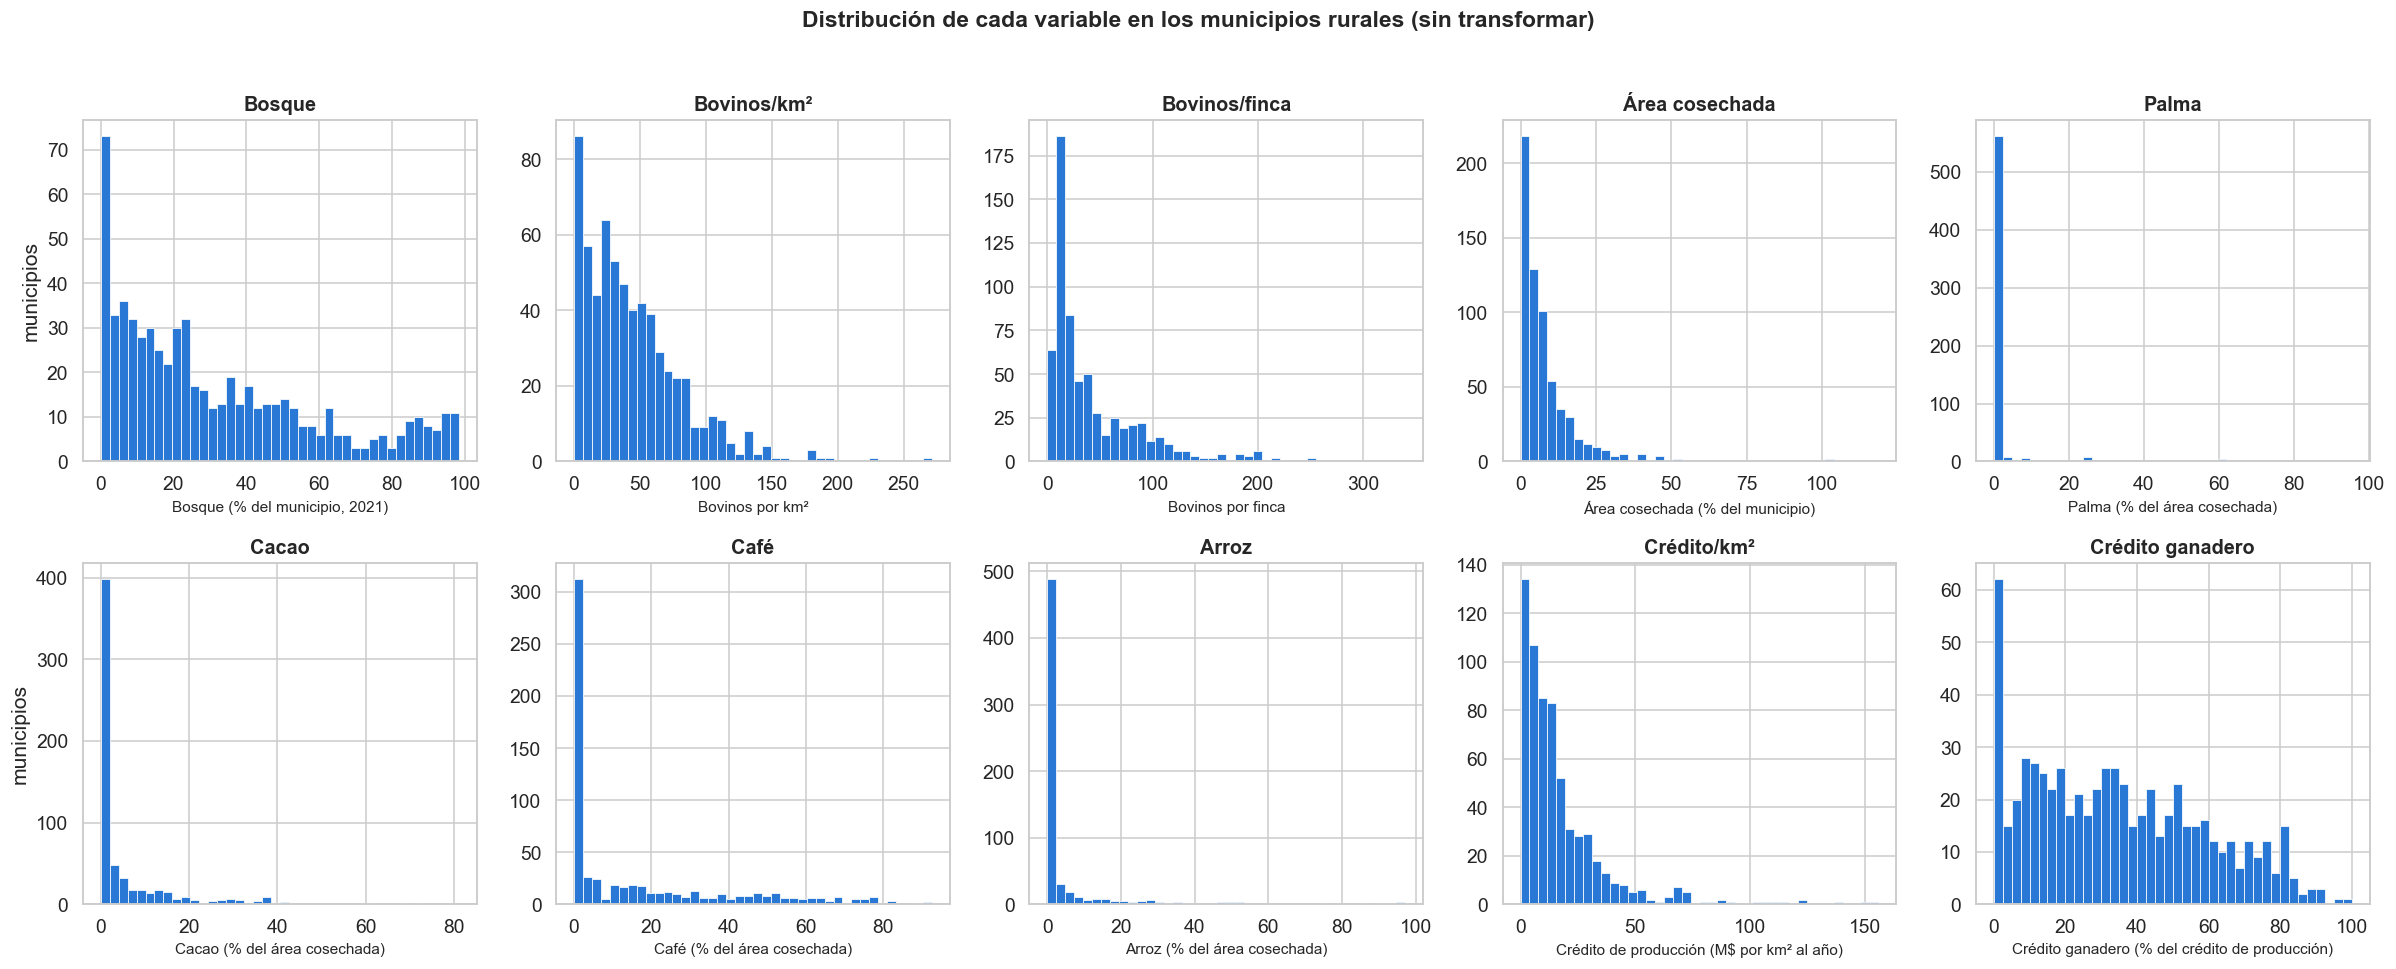

,mediana,media,asimetría,% de municipios en 0
"Bosque (% del municipio, 2021)",22.93,31.49,0.89,0.16
Bovinos por km²,36.09,44.19,1.46,2.34
Bovinos por finca,24.43,43.29,2.10,2.34
Área cosechada (% del municipio),5.30,8.59,4.19,2.97
Palma (% del área cosechada),0.00,5.25,3.59,86.41
Cacao (% del área cosechada),0.54,6.52,2.94,40.94
Café (% del área cosechada),2.99,16.28,1.35,41.41
Arroz (% del área cosechada),0.00,6.13,3.61,68.59
Crédito de producción (M$ por km² al año),11.31,17.21,2.97,1.88
Crédito ganadero (% del crédito de producción),31.62,34.28,0.41,7.34


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, c in zip(axes.flat, VARIABLES):
    ax.hist(X[c].dropna(), bins=40, color=PALETA[0], edgecolor="white", linewidth=0.5)
    ax.set_title(CORTOS[c])
    ax.set_xlabel(NOMBRES[c], fontsize=10)
axes[0, 0].set_ylabel("municipios")
axes[1, 0].set_ylabel("municipios")
fig.suptitle("Distribución de cada variable en los municipios rurales (sin transformar)", weight="bold", fontsize=15)
plt.tight_layout(rect=(0, 0, 1, .96))
plt.show()

pd.DataFrame({"mediana": X.median(), "media": X.mean(), "asimetría": X.skew(),
              "% de municipios en 0": 100 * (X == 0).mean()}).rename(index=NOMBRES).round(2)

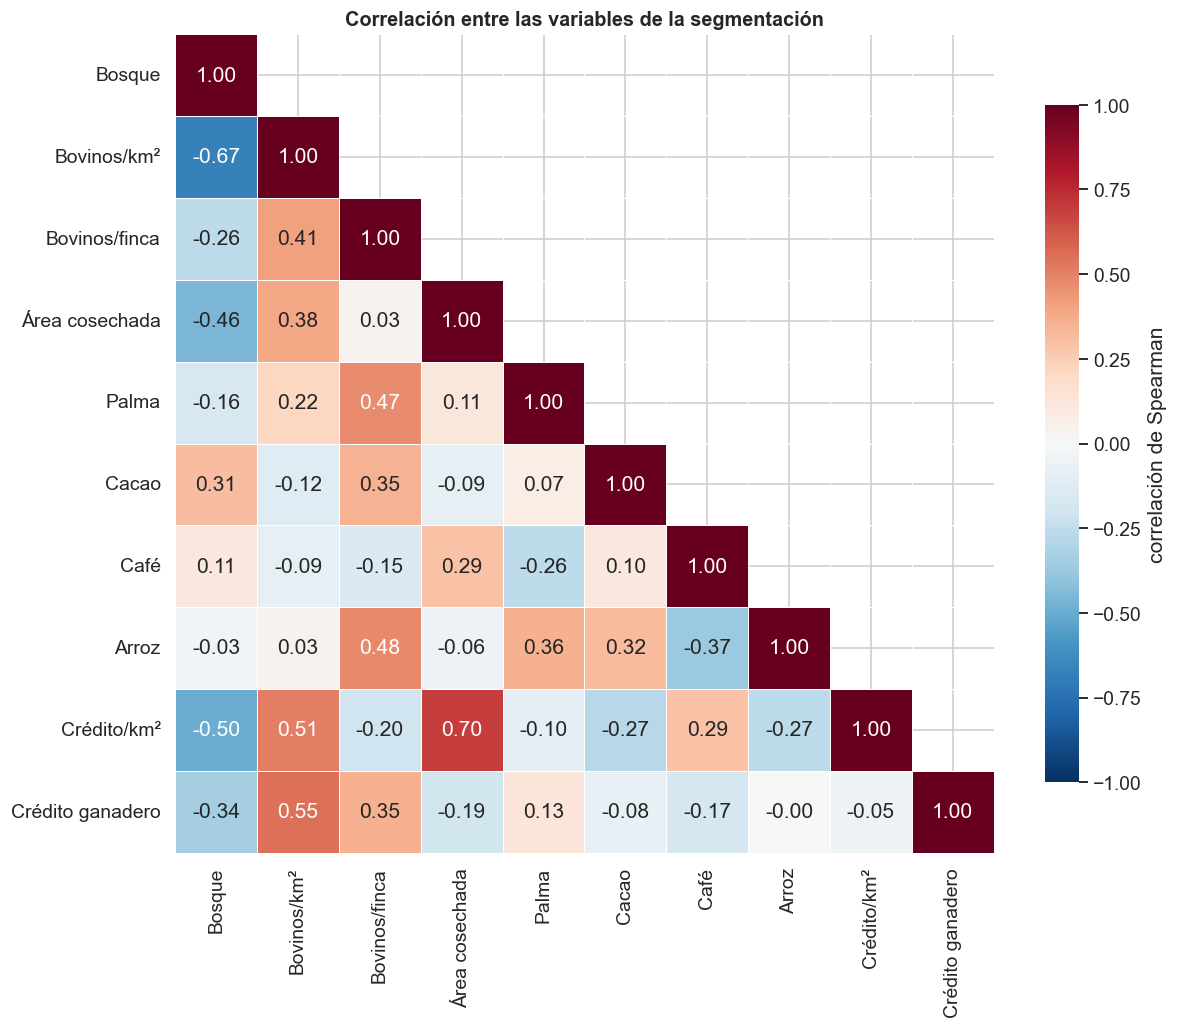

In [4]:
correlacion = X.rename(columns=CORTOS).corr("spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlacion, mask=np.triu(np.ones_like(correlacion, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax,
            cbar_kws={"label": "correlación de Spearman", "shrink": .8})
ax.set_title("Correlación entre las variables de la segmentación")
plt.show()

**Qué se ve.**

- Casi todas las variables tienen una **cola larga a la derecha**: muchos municipios con poco y unos pocos con
  mucho. La más asimétrica es el área cosechada (asimetría de 4,2). Le siguen el arroz, la palma, el crédito por km²
  y el cacao, entre 2,9 y 3,6.
- Los cultivos tienen **muchos ceros**:
  - el 86 % de los municipios no cosecha palma;
  - el 69 % no cosecha arroz;
  - cerca del 41 % no cosecha cacao, y otro tanto no cosecha café.

  Son cultivos que están en unos municipios y no en otros, y eso es justo lo que puede formar grupos.
- Ningún par de variables está tan correlacionado como para repetir información. Las correlaciones más fuertes son:
  - la del área cosechada con el crédito por km² (0,70): donde se cultiva más llega más crédito;
  - la del bosque con los bovinos por km² (−0,67): donde hay más ganado queda menos bosque.

### Preprocesamiento

**Cómo se hace.** Todo va en un `Pipeline` de scikit-learn, para que la transformación quede en un solo objeto que se
puede volver a aplicar igual. Tiene tres pasos:

1. **Imputación** de los pocos valores vacíos con la mediana.
2. **log(1 + x)** a las cuatro intensidades con cola larga: bovinos por km², bovinos por finca, área cosechada y
   crédito por km².
   - El logaritmo hace que pasar de 10 a 100 pese lo mismo que pasar de 100 a 1.000.
   - El +1 deja los ceros en 0.
   - Las participaciones (de 0 a 100 %) y el bosque se dejan como están.
3. **Estandarización**: cada variable queda con media 0 y desviación estándar 1, para que todas pesen lo mismo en la
   distancia.

**Cómo leer el gráfico.** Cada caja es una variable ya transformada. Los puntos sueltos son municipios lejos del
resto.

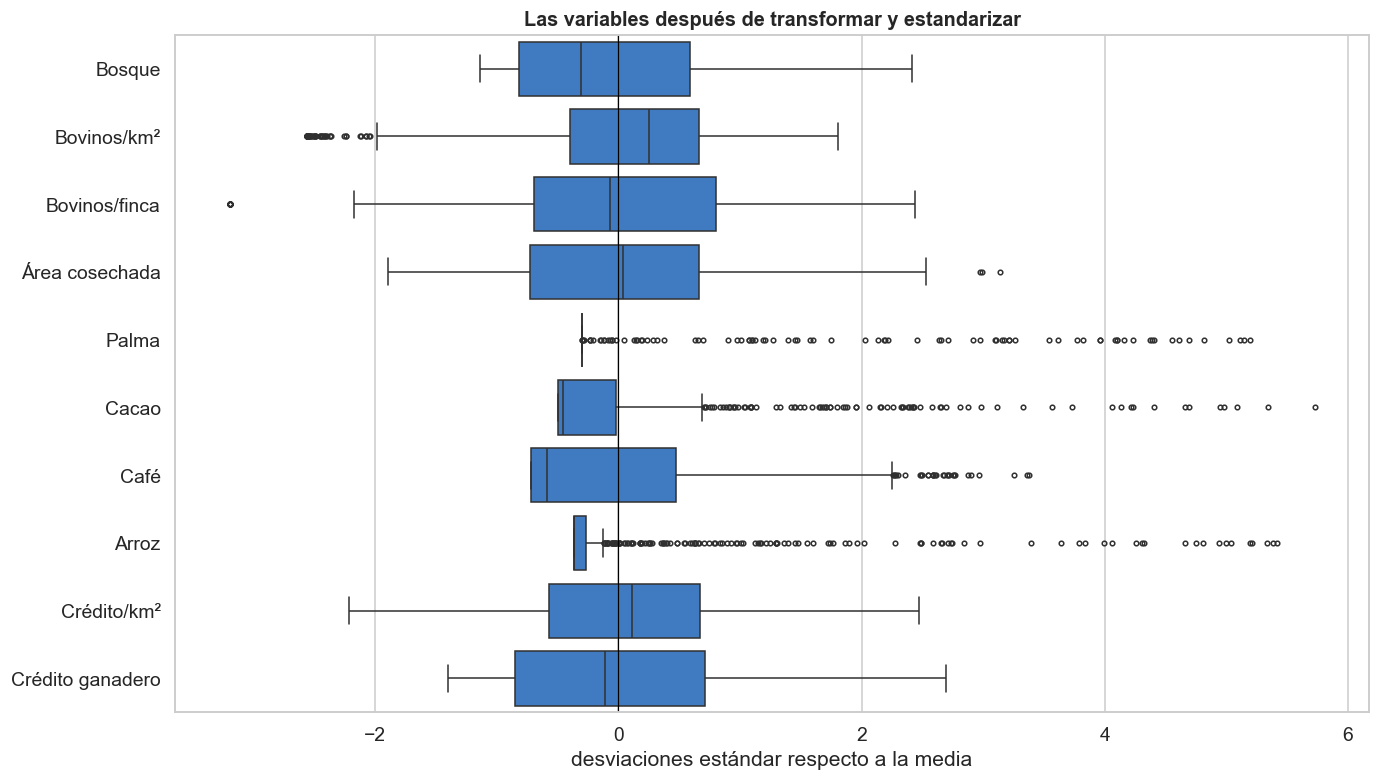

Municipios a más de 3 desviaciones estándar de la media, por variable:
Bosque               0
Bovinos/km²          0
Bovinos/finca       15
Área cosechada       1
Palma               29
Cacao               16
Café                 3
Arroz               20
Crédito/km²          0
Crédito ganadero     0


In [5]:
LOG = ["bovinos", "hato", "agricola", "credito"]
preproceso = make_pipeline(
    SimpleImputer(strategy="median"),
    ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), LOG)],
                      remainder="passthrough", verbose_feature_names_out=False),
    StandardScaler(),
).set_output(transform="pandas")
Z = preproceso.fit_transform(X)[VARIABLES]
Zv = Z.to_numpy()

fig, ax = plt.subplots(figsize=(14, 8))
sns.boxplot(data=Z.rename(columns=CORTOS), orient="h", color=PALETA[0], fliersize=3, ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Las variables después de transformar y estandarizar", xlabel="desviaciones estándar respecto a la media")
plt.show()
print("Municipios a más de 3 desviaciones estándar de la media, por variable:")
print((Z.abs() > 3).sum().rename(CORTOS).to_string())

**Qué se ve.**

- Con el logaritmo, ningún municipio queda a más de 3 desviaciones estándar en bosque, bovinos por km² o crédito.
- Los que siguen lejos del resto son de dos tipos:
  - municipios donde un cultivo pesa mucho: 29 en palma, 20 en arroz y 16 en cacao;
  - municipios con hatos muy grandes: 15.

No son errores: son municipios donde un cultivo o la ganadería dominan, y eso es justo lo que la segmentación debe
ver. Por eso se dejan.

## 3. ¿Hay grupos? ¿Cuántos?

**La pregunta.** ¿Los municipios forman grupos de verdad, o cualquier partición sería arbitraria? Y si hay grupos,
¿cuántos?

**Cómo se hace.** Se corre K-means con k = 2 a 10 segmentos y se miran tres criterios. Cada k se corre con 50
arranques distintos, para no quedarse en una mala solución. Ningún criterio basta solo, así que se miran juntos:

- **Inercia (codo).** Es la suma de las distancias de cada municipio al centro de su grupo. Siempre baja al subir k.
  Se busca el punto donde deja de bajar rápido.
- **Silueta.** Va de −1 a 1 y mide qué tan cerca está cada municipio de su grupo frente al grupo vecino.
  - Se compara con la silueta de **datos sin estructura**: las mismas variables, pero cada una barajada por
    separado. Esos datos tienen las mismas distribuciones, pero ningún grupo real.
  - Si la silueta de los datos no supera a la de los barajados, los "grupos" serían un artificio.
- **Estabilidad por bootstrap.**
  - Se remuestrean los municipios 100 veces, se vuelve a segmentar y se compara con la segmentación original.
  - La comparación usa el índice de Rand ajustado (ARI): 1 es idéntica y 0 es como al azar.
  - Una segmentación útil no debe cambiar mucho con una muestra un poco distinta. Se toma 0,85 como referencia de
    "estable".

**Cómo leer el gráfico.** Cada panel es un criterio, con k en el eje horizontal.

- En la silueta, la franja gris es lo que da el azar.
- En la estabilidad, la franja azul va del percentil 10 a la media de los 100 remuestreos.

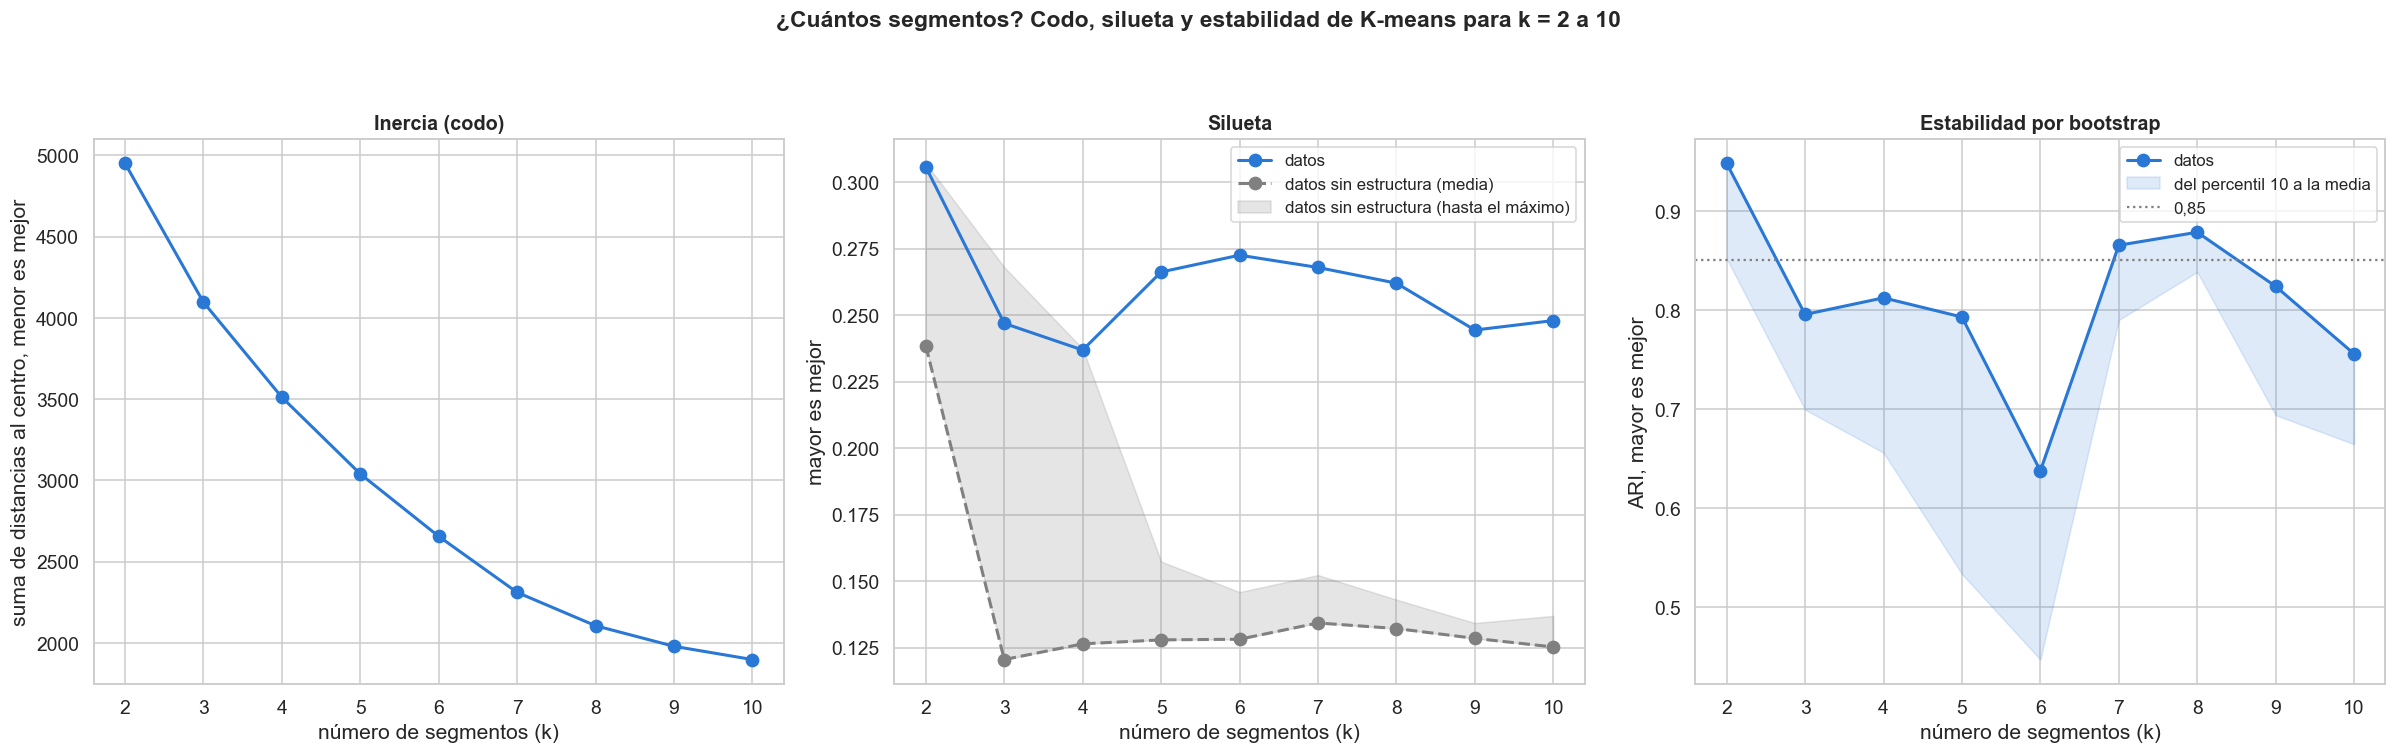

,inercia,silueta,silueta sin estructura,silueta sin estructura (máx.),estabilidad (ARI medio),"estabilidad (ARI, percentil 10)",segmento más pequeño
k,,,,,,,
2,4950.956,0.306,0.238,0.307,0.948,0.852,100
3,4096.132,0.247,0.120,0.268,0.796,0.699,92
4,3511.048,0.237,0.126,0.237,0.812,0.656,78
5,3039.350,0.266,0.128,0.157,0.793,0.534,36
6,2655.052,0.273,0.128,0.146,0.638,0.447,37
7,2309.968,0.268,0.134,0.152,0.865,0.790,35
8,2104.972,0.262,0.132,0.143,0.879,0.838,35
9,1978.275,0.244,0.128,0.134,0.824,0.694,33
10,1896.700,0.248,0.125,0.137,0.756,0.665,17


In [6]:
def estabilidad(Z, k, B=100):
    """ARI entre la segmentacion de todos los datos y la de B remuestreos bootstrap (una cifra por remuestreo)."""
    rng = np.random.default_rng(SEMILLA)
    completa = KMeans(k, n_init=20, random_state=SEMILLA).fit_predict(Z)
    aris = []
    for b in range(B):
        muestra = rng.choice(len(Z), len(Z), replace=True)
        modelo = KMeans(k, n_init=10, random_state=b).fit(Z[muestra])
        aris.append(adjusted_rand_score(completa, modelo.predict(Z)))
    return np.array(aris)


def silueta_sin_estructura(Z, k, P=20):
    """Silueta de K-means cuando cada variable se baraja por separado: mismas distribuciones, sin grupos."""
    rng = np.random.default_rng(SEMILLA)
    siluetas = []
    for p in range(P):
        barajado = np.column_stack([rng.permutation(columna) for columna in Z.T])
        etiquetas = KMeans(k, n_init=10, random_state=p).fit_predict(barajado)
        siluetas.append(silhouette_score(barajado, etiquetas))
    return np.array(siluetas)


filas = []
for k in range(2, 11):
    modelo = KMeans(k, n_init=50, random_state=SEMILLA).fit(Zv)
    nula = silueta_sin_estructura(Zv, k)
    ari = estabilidad(Zv, k)
    filas.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(Zv, modelo.labels_),
                  "silueta sin estructura": nula.mean(), "silueta sin estructura (máx.)": nula.max(),
                  "estabilidad (ARI medio)": ari.mean(), "estabilidad (ARI, percentil 10)": np.percentile(ari, 10),
                  "segmento más pequeño": np.bincount(modelo.labels_).min()})
indices = pd.DataFrame(filas).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
ks = indices.index
graficos = [("inercia", "Inercia (codo)", "suma de distancias al centro, menor es mejor"),
            ("silueta", "Silueta", "mayor es mejor"),
            ("estabilidad (ARI medio)", "Estabilidad por bootstrap", "ARI, mayor es mejor")]
for ax, (c, titulo, eje) in zip(axes, graficos):
    ax.plot(ks, indices[c], marker="o", color=PALETA[0], lw=2, ms=8, label="datos")
    ax.set(title=titulo, xlabel="número de segmentos (k)", ylabel=eje, xticks=ks)
axes[1].plot(ks, indices["silueta sin estructura"], marker="o", color="grey", lw=2, ms=8, ls="--",
             label="datos sin estructura (media)")
axes[1].fill_between(ks, indices["silueta sin estructura"], indices["silueta sin estructura (máx.)"],
                     color="grey", alpha=.2, label="datos sin estructura (hasta el máximo)")
axes[1].legend(fontsize=11)
axes[2].fill_between(ks, indices["estabilidad (ARI, percentil 10)"], indices["estabilidad (ARI medio)"],
                     color=PALETA[0], alpha=.15, label="del percentil 10 a la media")
axes[2].axhline(0.85, color="grey", ls=":", lw=1.5, label="0,85")
axes[2].legend(fontsize=11)
fig.suptitle("¿Cuántos segmentos? Codo, silueta y estabilidad de K-means para k = 2 a 10", weight="bold",
             fontsize=15)
plt.tight_layout(rect=(0, 0, 1, .93))
plt.show()
indices.round(3)

### La decisión: 8 segmentos

**Qué se ve.**

- **Sí hay grupos, pero no muy marcados.**
  - Desde k = 5, la silueta de los datos está entre 0,24 y 0,27. Es el doble de la de los datos barajados
    (alrededor de 0,13) y supera su máximo. Los grupos no son un artificio.
  - Aun así, 0,26 está en el límite inferior de lo que la referencia usual (Kaufman y Rousseeuw, 1990) llama una
    estructura débil. Los segmentos existen, pero sus fronteras no son nítidas: hay municipios a medio camino entre
    dos segmentos.
- **k = 2 no sirve, aunque tenga la silueta más alta.** Su silueta (0,306) es igual al máximo de los datos barajados
  (0,307). Además, solo separa los municipios de selva del resto.
- **El codo no es un quiebre limpio.** Hasta k = 7, cada segmento nuevo baja la inercia en más de 340. Desde k = 8
  baja cada vez menos: 205, 127 y 82.
- **La estabilidad decide.**
  - Aparte de k = 2, solo k = 7 (0,87) y k = 8 (0,88) pasan de 0,85.
  - k = 8 es el más estable de los dos y el que tiene el percentil 10 más alto (0,84): aun en los peores
    remuestreos, la segmentación casi no cambia.
  - Con k = 6, en cambio, la estabilidad cae a 0,64.

Se eligen **8 segmentos**. Frente a 7, el octavo separa del resto de los ganaderos a los municipios con mucho bosque y
poco ganado.

In [7]:
K = 8
km = KMeans(K, n_init=100, random_state=SEMILLA).fit(Zv)
# Las etiquetas de K-means son arbitrarias: se numeran de 1 a K de mas a menos bosque (mediana)
orden = X.bosque.groupby(km.labels_).median().sort_values(ascending=False).index
RECODIFICAR = {vieja: nueva for nueva, vieja in enumerate(orden, start=1)}
segmento = pd.Series(km.labels_, index=X.index).map(RECODIFICAR).rename("segmento")
SEGS = list(range(1, K + 1))
COLOR = dict(zip(SEGS, PALETA))

perfil = X.groupby(segmento).median()
perfil.insert(0, "municipios", segmento.value_counts().sort_index())
perfil.rename(columns=CORTOS).round(1)

,municipios,Bosque,Bovinos/km²,Bovinos/finca,Área cosechada,Palma,Cacao,Café,Arroz,Crédito/km²,Crédito ganadero
segmento,,,,,,,,,,,
1,64,88.9,0.1,8.3,0.5,0.0,2.0,0.0,0.3,0.3,0.0
2,86,54.7,14.9,31.7,1.8,0.0,1.1,6.9,0.0,4.8,40.0
3,47,36.5,41.6,38.0,3.6,0.0,38.8,5.0,0.0,10.4,34.7
4,123,28.9,26.0,19.8,8.0,0.0,1.2,52.7,0.0,14.7,17.1
5,142,13.2,51.3,12.9,11.2,0.0,0.0,5.0,0.0,30.4,30.1
6,42,9.9,57.9,115.8,8.4,67.3,0.5,0.0,5.0,7.9,37.3
7,101,8.3,68.7,73.3,3.0,0.0,0.0,0.0,0.0,8.4,70.7
8,35,6.6,53.8,75.0,8.8,0.0,0.8,0.0,69.8,13.5,23.2


### Los nombres de los segmentos

Los números que pone K-means no significan nada, así que los segmentos se numeran de más a menos bosque. Los
nombres se pusieron después de mirar los perfiles de la sección 5, y cada uno describe el rasgo que más distingue
al grupo.

In [8]:
SEGMENTOS = {
    1: "1. Selva sin actividad agropecuaria",
    2: "2. Bosque con ganadería dispersa",
    3: "3. Cacao y bosque",
    4: "4. Cafetero",
    5: "5. Minifundio con mucho crédito",
    6: "6. Palmero",
    7: "7. Ganadero",
    8: "8. Arrocero",
}
nombre_segmento = segmento.map(SEGMENTOS)
ETIQUETAS = [SEGMENTOS[s] for s in SEGS]
COLOR_NOMBRE = {SEGMENTOS[s]: COLOR[s] for s in SEGS}

## 4. ¿Qué tan robusta es la segmentación?

**La pregunta.** ¿Cada segmento es real, o aparece solo con estos municipios exactos y se deshace con una muestra un
poco distinta?

**Cómo se hace.** Se mide la **estabilidad de cada segmento** (Hennig, 2007):

1. Se remuestrean los municipios 200 veces y en cada remuestreo se vuelve a segmentar.
2. Para cada segmento original se busca el más parecido en la nueva segmentación.
3. El parecido se mide con el índice de Jaccard: los municipios en común sobre los municipios en cualquiera de los
   dos. Va de 0 (ninguno en común) a 1 (los mismos municipios).
4. Se promedia el Jaccard de los 200 remuestreos.

La lectura usual es:

- más de 0,85: muy estable;
- de 0,75 a 0,85: estable;
- de 0,6 a 0,75: un patrón con dudas;
- menos de 0,5: el segmento se disuelve.

La estabilidad de la sección 3 mide la segmentación completa. Esta mide cada segmento por separado.

In [9]:
def jaccard_bootstrap(Z, etiquetas, k, B=200):
    """Estabilidad de cada segmento (Hennig, 2007): Jaccard medio con el segmento mas parecido en B bootstrap."""
    rng = np.random.default_rng(SEMILLA)
    jaccard = np.full((B, k), np.nan)
    for b in range(B):
        muestra = rng.choice(len(Z), len(Z), replace=True)
        modelo = KMeans(k, n_init=10, random_state=b).fit(Z[muestra])
        unicos = np.unique(muestra)
        nuevas, viejas = modelo.predict(Z[unicos]), etiquetas[unicos]
        for s in range(k):
            en_s = viejas == s
            if en_s.any():
                jaccard[b, s] = max((en_s & (nuevas == t)).sum() / (en_s | (nuevas == t)).sum() for t in range(k))
    return np.nanmean(jaccard, axis=0)



etiquetas0 = segmento.to_numpy() - 1
estab_seg = pd.DataFrame({"municipios": segmento.value_counts().sort_index().values,
                          "Jaccard medio (bootstrap)": jaccard_bootstrap(Zv, etiquetas0, K)}, index=ETIQUETAS)
estab_seg["lectura"] = pd.cut(estab_seg["Jaccard medio (bootstrap)"], [0, .5, .6, .75, .85, 1],
                              labels=["se disuelve", "débil", "patrón con dudas", "estable", "muy estable"])
estab_seg.round(2)

,municipios,Jaccard medio (bootstrap),lectura
1. Selva sin actividad agropecuaria,64,0.97,muy estable
2. Bosque con ganadería dispersa,86,0.81,estable
3. Cacao y bosque,47,0.91,muy estable
4. Cafetero,123,0.93,muy estable
5. Minifundio con mucho crédito,142,0.90,muy estable
6. Palmero,42,0.96,muy estable
7. Ganadero,101,0.85,estable
8. Arrocero,35,0.92,muy estable


**Qué se ve.**

- **Los ocho segmentos son estables.** Ninguno se disuelve ni queda como un patrón con dudas.
- **Seis son muy estables**, con un Jaccard por encima de 0,85:
  - los más nítidos son la selva (0,97) y el palmero (0,96);
  - les siguen el cafetero (0,93), el arrocero (0,92), el cacaotero (0,91) y el minifundio (0,90).
- **Los otros dos son estables, pero menos nítidos**: el ganadero (0,85) y el de bosque con ganadería dispersa
  (0,81). Con una muestra un poco distinta, algunos de sus municipios cambian de segmento.

En resumen, los segmentos no dependen de qué municipios exactos entren en la muestra. El de bosque con ganadería
dispersa y el ganadero deben leerse como tipos de municipio con fronteras menos nítidas.

## 5. Perfil de cada segmento

**La pregunta.** ¿Qué distingue a cada segmento?

**Cómo se hace.** Hay tres formas de verlo:

- El **centro** de cada segmento en las variables estandarizadas: cuántas desviaciones estándar está por encima o
  por debajo del municipio rural promedio.
- La **mediana** de cada variable, en sus unidades originales.
- Los municipios en los **dos primeros componentes principales**, que resumen las diez variables en dos ejes.

**Cómo leer el mapa de calor.** En rojo, el segmento está por encima del promedio en esa variable; en azul, por
debajo. El número es la distancia en desviaciones estándar.

**Cómo leer los componentes principales.** El primer panel muestra hacia dónde crece cada variable. En los demás,
cada segmento va en su color sobre el resto de municipios en gris.

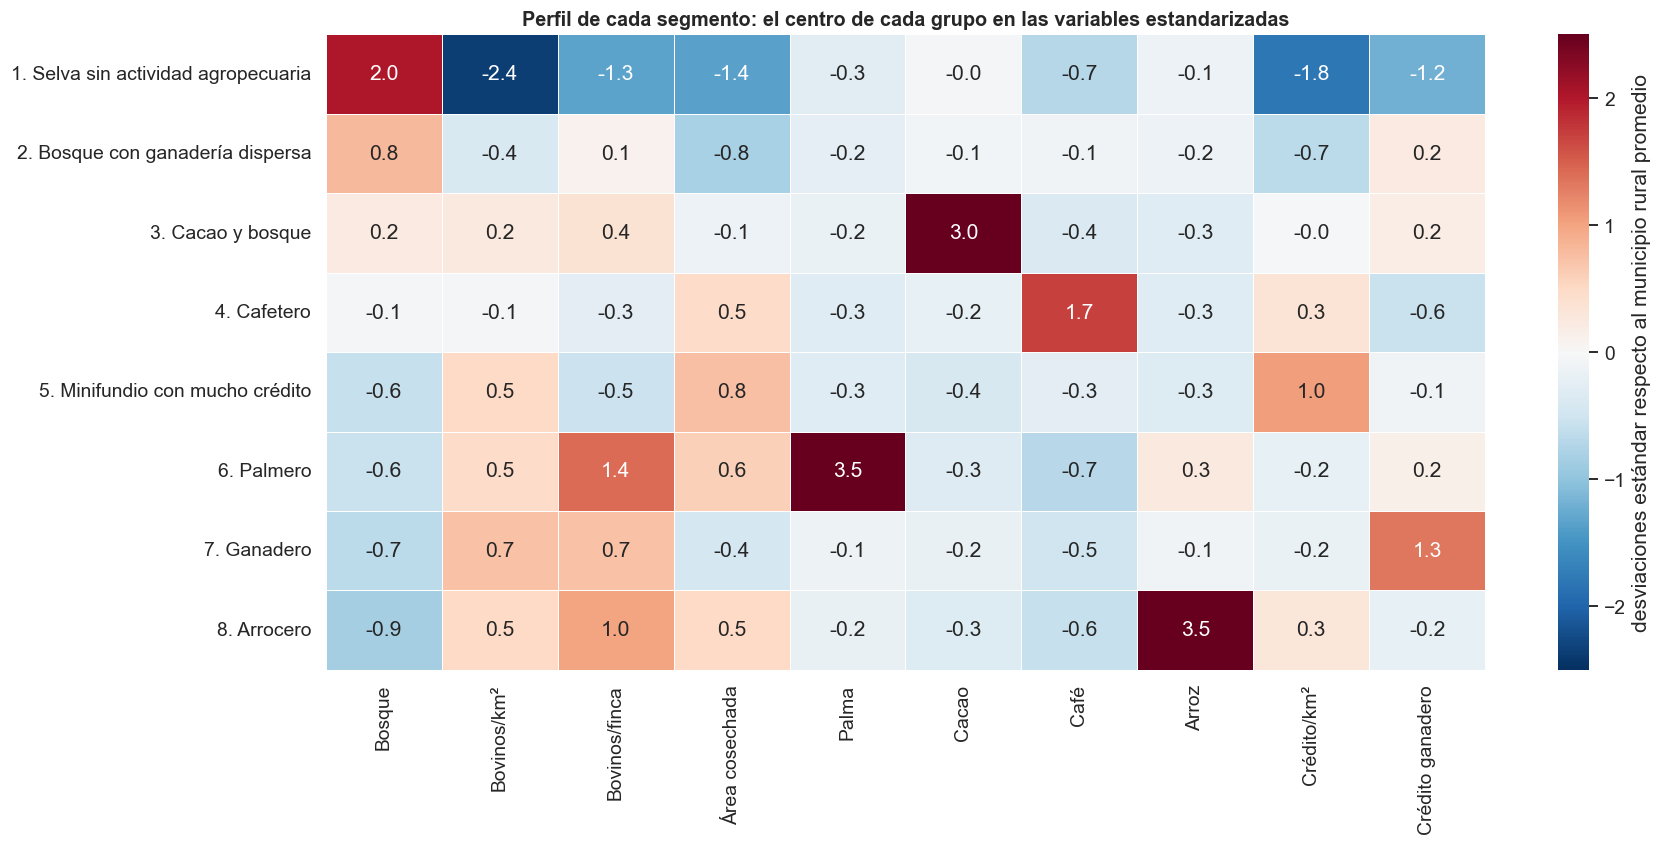

segmento,1. Selva sin actividad agropecuaria,2. Bosque con ganadería dispersa,3. Cacao y bosque,4. Cafetero,5. Minifundio con mucho crédito,6. Palmero,7. Ganadero,8. Arrocero
municipios,64.0,86.0,47.0,123.0,142.0,42.0,101.0,35.0
% de los municipios,10.0,13.4,7.3,19.2,22.2,6.6,15.8,5.5
área mediana (km²),1912.5,850.0,500.0,300.0,150.0,1025.0,450.0,800.0
"Bosque (% del municipio, 2021)",88.9,54.7,36.5,28.9,13.2,9.9,8.3,6.6
Bovinos por km²,0.1,14.9,41.6,26.0,51.3,57.9,68.7,53.8
Bovinos por finca,8.3,31.7,38.0,19.8,12.9,115.8,73.3,75.0
Área cosechada (% del municipio),0.5,1.8,3.6,8.0,11.2,8.4,3.0,8.8
Palma (% del área cosechada),0.0,0.0,0.0,0.0,0.0,67.3,0.0,0.0
Cacao (% del área cosechada),2.0,1.1,38.8,1.2,0.0,0.5,0.0,0.8
Café (% del área cosechada),0.0,6.9,5.0,52.7,5.0,0.0,0.0,0.0


In [10]:
centros = Z.groupby(nombre_segmento).mean().rename(columns=CORTOS)
fig, ax = plt.subplots(figsize=(17, 7.5))
sns.heatmap(centros, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5, linewidths=0.5, ax=ax,
            cbar_kws={"label": "desviaciones estándar respecto al municipio rural promedio"})
ax.set(title="Perfil de cada segmento: el centro de cada grupo en las variables estandarizadas", ylabel="",
       xlabel="")
plt.show()

mediana = X.groupby(nombre_segmento).median().rename(columns=NOMBRES)
mediana.insert(0, "municipios", nombre_segmento.value_counts())
mediana.insert(1, "% de los municipios", 100 * nombre_segmento.value_counts(normalize=True))
mediana.insert(2, "área mediana (km²)", (base.area_ha / 100).groupby(nombre_segmento).median())
mediana.round(1).T

Varianza explicada por cada componente (%): [32.4 19.8 12.2 10.   9.4  7.9  3.   2.3  2.1  0.8]
Los dos primeros explican el 52 %.


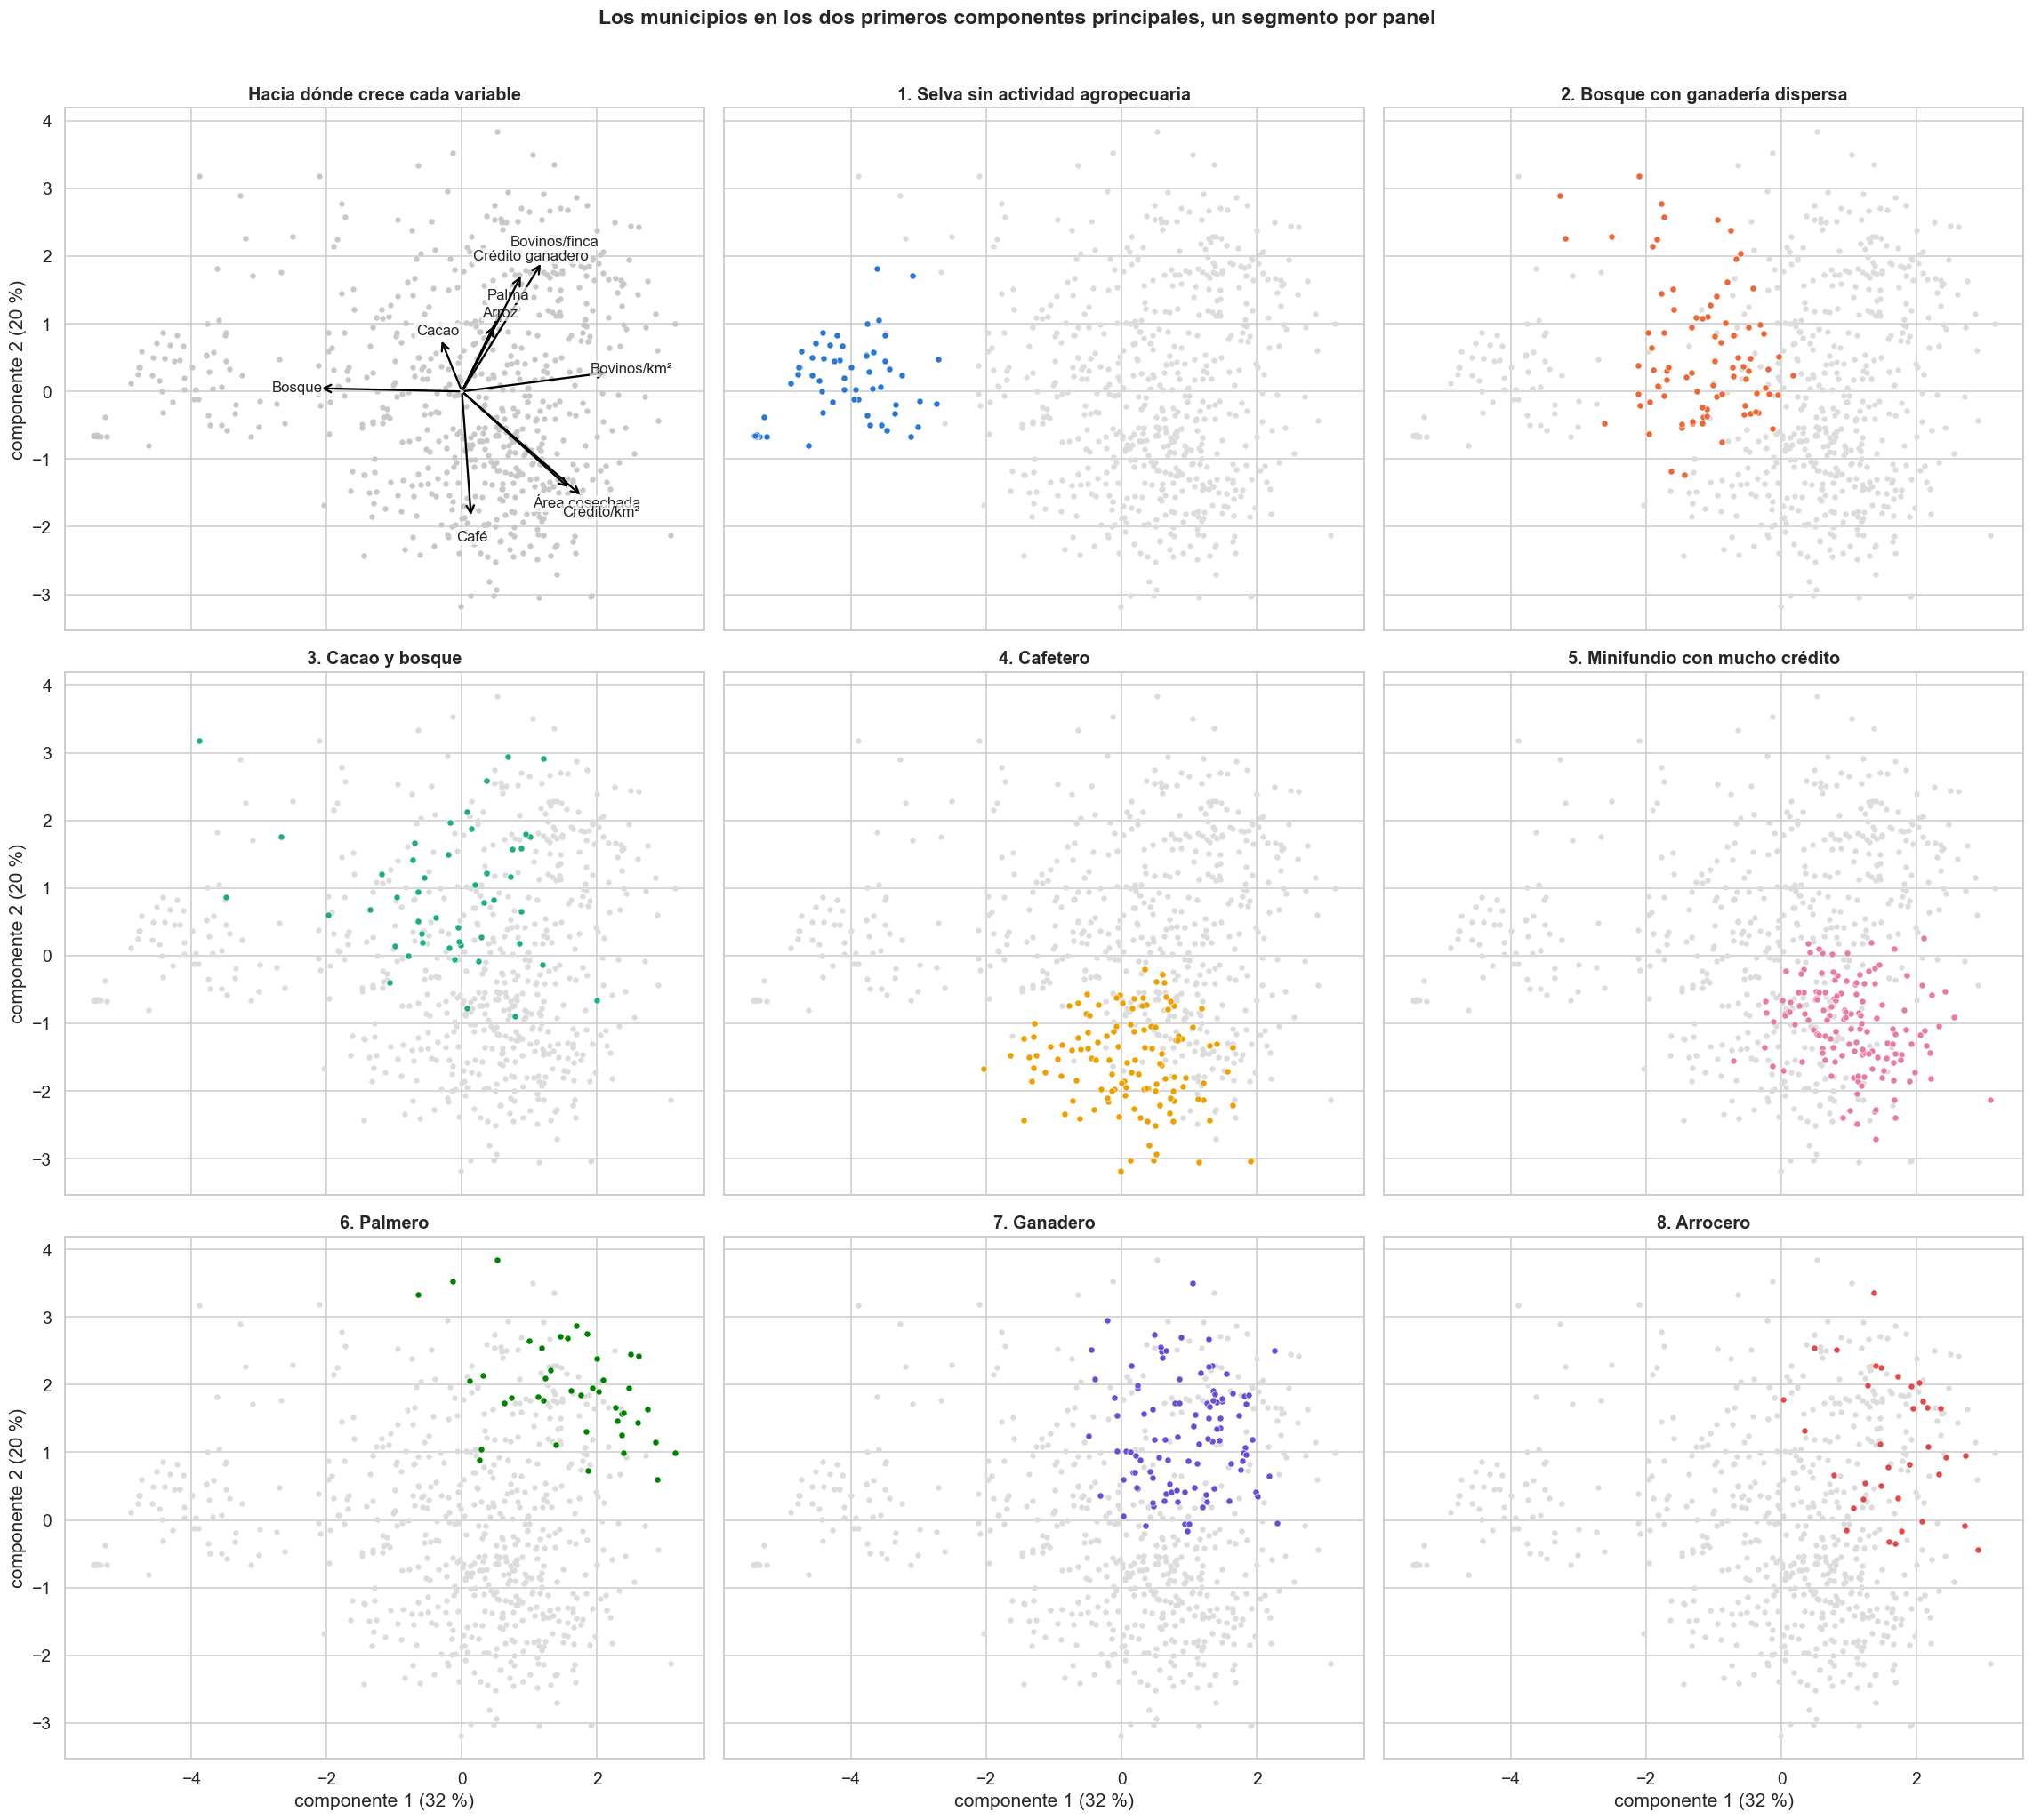

,componente 1,componente 2,componente 3
"Bosque (% del municipio, 2021)",-0.50,0.01,0.06
Bovinos por km²,0.52,0.07,-0.23
Bovinos por finca,0.28,0.45,0.12
Área cosechada (% del municipio),0.38,-0.34,0.28
Palma (% del área cosechada),0.14,0.29,0.43
Cacao (% del área cosechada),-0.07,0.18,-0.32
Café (% del área cosechada),0.03,-0.44,-0.12
Arroz (% del área cosechada),0.12,0.24,0.53
Crédito de producción (M$ por km² al año),0.42,-0.37,-0.06
Crédito ganadero (% del crédito de producción),0.21,0.41,-0.52


In [11]:
pca = PCA(random_state=SEMILLA).fit(Zv)
coordenadas = pca.transform(Zv)[:, :2]
var = 100 * pca.explained_variance_ratio_
print("Varianza explicada por cada componente (%):", np.round(var, 1))
print(f"Los dos primeros explican el {var[:2].sum():.0f} %.")

fig, axes = plt.subplots(3, 3, figsize=(21, 19), sharex=True, sharey=True)
ax = axes.flat[0]
ax.scatter(*coordenadas.T, s=10, color="#c8c8c8")
# Las flechas se escalan para que la mas larga quepa dentro del panel
margen = min(-coordenadas.min(axis=0).max(), coordenadas.max(axis=0).min())
escala = 0.75 * margen / np.linalg.norm(pca.components_[:2], axis=0).max()
for c, (x, y) in zip(VARIABLES, pca.components_[:2].T):
    ax.annotate("", xy=(escala * x, escala * y), xytext=(0, 0),
                arrowprops={"arrowstyle": "->", "color": "black", "lw": 1.5})
    ax.text(1.15 * escala * x, 1.15 * escala * y, CORTOS[c], fontsize=11, ha="center", va="center",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.7, "pad": 1})
ax.set_title("Hacia dónde crece cada variable")
for ax, s in zip(axes.flat[1:], SEGS):
    ax.scatter(*coordenadas.T, s=10, color="#dcdcdc")
    ax.scatter(*coordenadas[segmento.values == s].T, s=22, color=COLOR[s], edgecolor="white", linewidth=0.4)
    ax.set_title(SEGMENTOS[s])
for ax in axes[-1]:
    ax.set_xlabel(f"componente 1 ({var[0]:.0f} %)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"componente 2 ({var[1]:.0f} %)")
fig.suptitle("Los municipios en los dos primeros componentes principales, un segmento por panel", weight="bold",
             fontsize=15)
plt.tight_layout(rect=(0, 0, 1, .97))
plt.show()
pd.DataFrame(pca.components_[:3].T, index=[NOMBRES[c] for c in VARIABLES],
             columns=["componente 1", "componente 2", "componente 3"]).round(2)

### Dónde están los segmentos

**Cómo se hace.** Para cada segmento se calcula qué % de sus municipios está en cada región, y cuáles son los
departamentos con más municipios. La región **no** entró en la segmentación. Si los segmentos se parecen a regiones,
es porque los perfiles productivos tienen geografía.

In [12]:
region = pd.crosstab(nombre_segmento, base.region, normalize="index").mul(100).round(0)
region["departamentos con más municipios"] = [
    ", ".join(f"{d} ({n})" for d, n in base.departamento[nombre_segmento == e].value_counts().head(4).items())
    for e in region.index]
region

region,Caribe,Centro Oriente,Centro Sur,Eje cafetero,Llano,Pacífico,departamentos con más municipios
segmento,,,,,,,
1. Selva sin actividad agropecuaria,0.0,0.0,17.0,3.0,22.0,58.0,"Chocó (23), Amazonas (11), Nariño (10), Guainí..."
2. Bosque con ganadería dispersa,7.0,28.0,15.0,12.0,19.0,20.0,"Boyacá (9), Antioquia (8), Meta (8), Nariño (8)"
3. Cacao y bosque,2.0,53.0,6.0,21.0,11.0,6.0,"Santander (16), Antioquia (8), Boyacá (5), Cun..."
4. Cafetero,2.0,34.0,25.0,17.0,1.0,21.0,"Santander (19), Cauca (18), Huila (17), Antioq..."
5. Minifundio con mucho crédito,1.0,74.0,4.0,8.0,1.0,11.0,"Boyacá (48), Cundinamarca (34), Santander (19)..."
6. Palmero,40.0,17.0,0.0,2.0,40.0,0.0,"Meta (12), Cesar (7), Bolívar (6), Magdalena (4)"
7. Ganadero,41.0,25.0,14.0,13.0,5.0,3.0,"Boyacá (18), Magdalena (14), Antioquia (12), B..."
8. Arrocero,31.0,0.0,37.0,6.0,26.0,0.0,"Tolima (8), Casanare (7), Huila (5), Bolívar (4)"


**Qué se ve.** Cada segmento tiene un rasgo que lo distingue. Las cifras son medianas.

1. **Selva sin actividad agropecuaria** (64 municipios).
   - Casi todo es bosque (89 %).
   - Casi no tiene ganado (0,1 bovinos por km²), cultivos (0,5 % del municipio) ni crédito (0,3 M$ por km²).
   - Son municipios grandes (1.900 km²) del Pacífico, como Chocó y Nariño, y de la Amazonía y la Orinoquía
     oriental, como Amazonas, Guainía y Vaupés. 18 de los 64 son corregimientos departamentales.
2. **Bosque con ganadería dispersa** (86).
   - Mucho bosque (55 %) y algo de ganado (15 bovinos por km², en hatos de 32).
   - Muy poca agricultura (1,8 %) y poco crédito (4,8 M$ por km²), del que el 40 % va a la ganadería.
   - Es el segmento más mezclado en geografía. Tiene el piedemonte amazónico (Caquetá, Guaviare, sur del Meta y
     Putumayo) y también municipios con bosque de los Andes y la costa.
3. **Cacao y bosque** (47).
   - El cacao es el 39 % del área cosechada, y el bosque, el 37 % del municipio.
   - Está sobre todo en Santander, Antioquia y Boyacá.
4. **Cafetero** (123).
   - El café es el 53 % del área cosechada.
   - Está en la cordillera: Santander, Cauca, Huila y Antioquia.
5. **Minifundio con mucho crédito** (142).
   - Es el segmento con más crédito por km²: 30 M$, el doble del siguiente.
   - Los hatos son muy pequeños (13 bovinos por finca), aunque hay bastante ganado por km² (51).
   - Tiene poco bosque (13 %) y la mayor área cosechada (11 %).
   - Son municipios pequeños (150 km²) de Boyacá, Cundinamarca y Santander.
6. **Palmero** (42).
   - La palma es el 67 % del área cosechada.
   - Tiene los hatos más grandes (116 bovinos por finca) y poco bosque (10 %).
   - Está en el Meta y en el Caribe: Cesar, Bolívar y Magdalena.
7. **Ganadero** (101).
   - Tiene la mayor densidad de ganado (69 bovinos por km²) y hatos grandes (73 por finca).
   - El 71 % del crédito va a la ganadería.
   - Casi no tiene bosque (8 %) y tiene poca agricultura (3 %).
   - Está sobre todo en el Caribe (Magdalena, Bolívar), en Boyacá y en Antioquia.
8. **Arrocero** (35).
   - El arroz es el 70 % del área cosechada.
   - Es el segmento con menos bosque (7 %).
   - Está en el Tolima, el Huila, Casanare y el Caribe.

Los perfiles tienen geografía, pero no son regiones. El ganadero y el de bosque con ganadería dispersa, por ejemplo,
están repartidos en cinco o seis regiones.

**Los componentes principales** resumen la mitad de la información (52 %) en dos ejes:

- El **componente 1** (32 %) va del bosque, a la izquierda, a la actividad agropecuaria intensa, a la derecha: más
  ganado por km², más crédito y más área cosechada. Es el eje que va de la selva al campo trabajado.
- El **componente 2** (20 %) separa dos cosas:
  - arriba, la ganadería de hatos grandes y los cultivos de llanura, como la palma y el arroz;
  - abajo, el café, el minifundio y el crédito por km².
- **Dónde queda cada segmento:**
  - la selva, sola a la izquierda;
  - el bosque con ganadería dispersa, entre la selva y el centro;
  - cafeteros y minifundio, abajo;
  - palmeros, arroceros y ganaderos, arriba a la derecha;
  - los cacaoteros, en el centro, mezclados con otros. En estos dos ejes no se distinguen porque el cacao pesa poco
    en los dos primeros componentes.

## 6. ¿Cuánto deforesta cada segmento?

**La pregunta.** ¿Los municipios con un mismo perfil productivo deforestan parecido? ¿Qué perfiles concentran la
deforestación?

**Cómo se hace.** La deforestación no se usó para formar los segmentos, así que esto es una **validación externa**:
si los segmentos deforestan distinto, el perfil productivo dice algo sobre la deforestación. Se usan tres medidas,
con el promedio de 2021 a 2025:

- **Tasa**: el % del bosque que se pierde cada año, según el IDEAM. Dice qué tan rápido se pierde el bosque que
  queda.
- **Hectáreas deforestadas por 100 km²**, según el IDEAM. Dice cuánta deforestación hay en el territorio.
- **Alertas de GFW por 100 km²**, como contraste con una fuente independiente.

**Cómo leer los gráficos.**

- **Cajas.** Cada caja va del primer al tercer cuartil y la raya es la mediana. La escala es logarítmica, pero
  incluye el 0.
- **Barras.** La gris es el % de municipios del segmento y la de color, el % de la deforestación que aporta. Si la de
  color es más larga, el segmento deforesta más de lo que le tocaría por su número de municipios.

In [13]:
total = deforestacion.def_total_ha.sum()
mayores = deforestacion.def_total_ha.groupby(nombre_segmento).nlargest(3)
resumen = pd.DataFrame({
    "municipios": nombre_segmento.value_counts(),
    "% de los municipios": 100 * nombre_segmento.value_counts(normalize=True),
    "% de la deforestación 2021-2025": 100 * deforestacion.def_total_ha.groupby(nombre_segmento).sum() / total,
    "tasa mediana (% del bosque por año)": deforestacion.tasa.groupby(nombre_segmento).median(),
    "mediana de ha deforestadas por 100 km² al año": deforestacion.def_100km2.groupby(nombre_segmento).median(),
    "mediana de alertas GFW (ha por 100 km² al año)": deforestacion.gfw_100km2.groupby(nombre_segmento).median(),
    "% de la deforestación del segmento en sus 5 municipios con más": deforestacion.def_total_ha.groupby(
        nombre_segmento).agg(lambda s: 100 * s.nlargest(5).sum() / s.sum()),
    "los 3 que más deforestan": {e: ", ".join(base.nombre[mayores[e].index]) for e in ETIQUETAS},
}).loc[ETIQUETAS]
print(f"Deforestación 2021-2025 en los {len(X)} municipios: {total:,.0f} ha")
resumen.round(2)

Deforestación 2021-2025 en los 640 municipios: 563,651 ha


,municipios,% de los municipios,% de la deforestación 2021-2025,tasa mediana (% del bosque por año),mediana de ha deforestadas por 100 km² al año,mediana de alertas GFW (ha por 100 km² al año),% de la deforestación del segmento en sus 5 municipios con más,los 3 que más deforestan
1. Selva sin actividad agropecuaria,64,10.00,12.13,0.08,5.96,5.90,36.03,"Cumaribo, Nóvita, Mitú"
2. Bosque con ganadería dispersa,86,13.44,53.45,0.08,3.99,9.57,56.40,"Cartagena del Chairá, La Macarena, Calamar"
3. Cacao y bosque,47,7.34,4.47,0.23,8.71,14.34,45.13,"Arauquita, Santa Rosa del Sur, Valle del Guamuez"
4. Cafetero,123,19.22,0.96,0.03,0.90,2.77,32.74,"El Tambo, Támara, Planadas"
5. Minifundio con mucho crédito,142,22.19,0.42,0.01,0.08,0.79,72.79,"Yolombó, Sonson, Bolívar"
6. Palmero,42,6.56,14.24,0.28,2.33,2.95,86.61,"Mapiripán, Tibú, Puerto Rico"
7. Ganadero,101,15.78,12.56,0.14,0.79,0.67,82.54,"San Vicente del Caguán, Remedios, Yondó"
8. Arrocero,35,5.47,1.77,0.26,0.73,0.52,68.89,"Zaragoza, Hato Corozal, Paz de Ariporo"


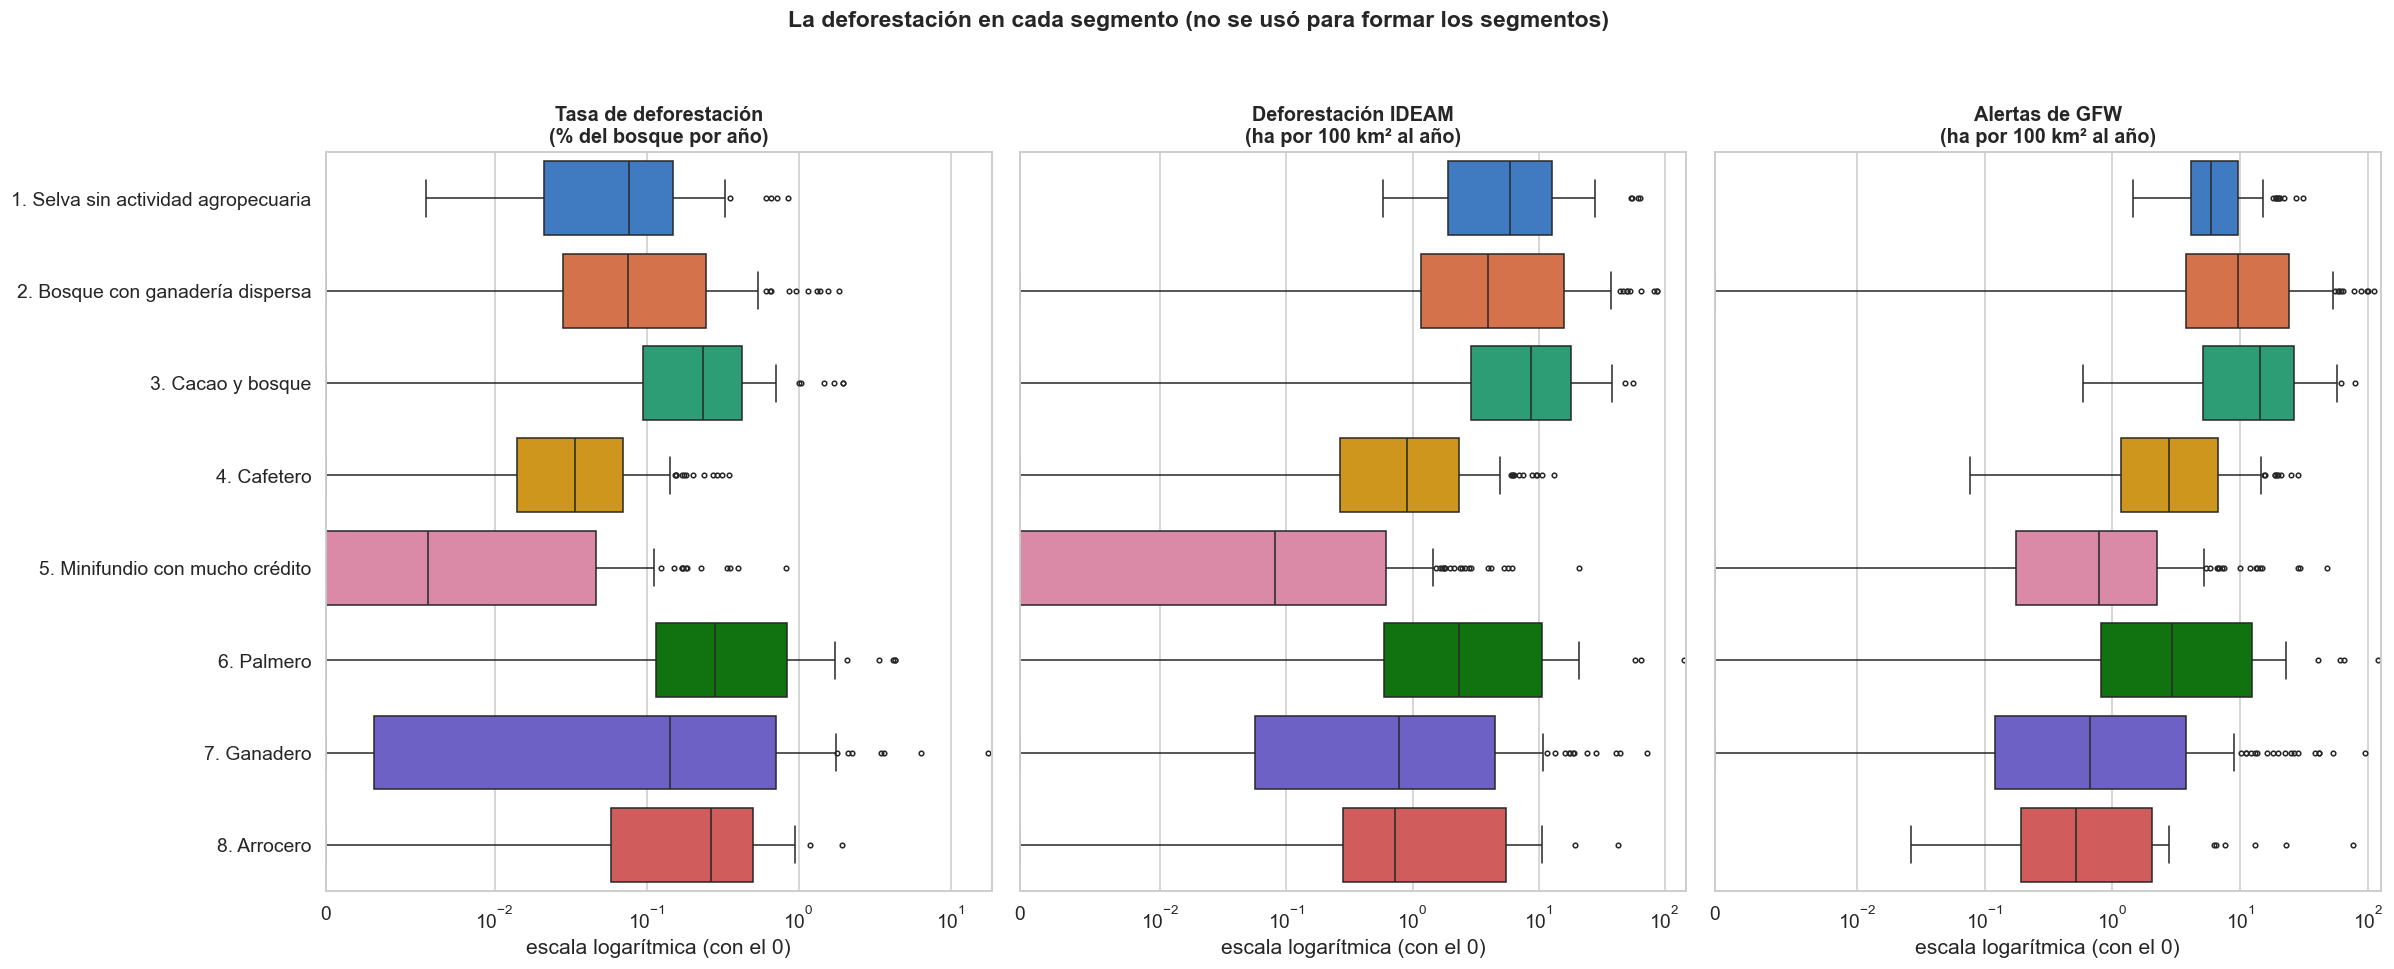

In [14]:
MEDIDAS = {"tasa": "Tasa de deforestación\n(% del bosque por año)",
           "def_100km2": "Deforestación IDEAM\n(ha por 100 km² al año)",
           "gfw_100km2": "Alertas de GFW\n(ha por 100 km² al año)"}
largo = deforestacion[list(MEDIDAS)].assign(segmento=nombre_segmento)
fig, axes = plt.subplots(1, 3, figsize=(22, 9), sharey=True)
for ax, (c, titulo) in zip(axes, MEDIDAS.items()):
    sns.boxplot(data=largo, x=c, y="segmento", order=ETIQUETAS, palette=COLOR_NOMBRE, fliersize=3, ax=ax)
    ax.set_xscale("symlog", linthresh=0.01)
    ax.set_xlim(left=0)
    ax.set(title=titulo, xlabel="escala logarítmica (con el 0)", ylabel="")
fig.suptitle("La deforestación en cada segmento (no se usó para formar los segmentos)", weight="bold", fontsize=15)
plt.tight_layout(rect=(0, 0, 1, .95))
plt.show()

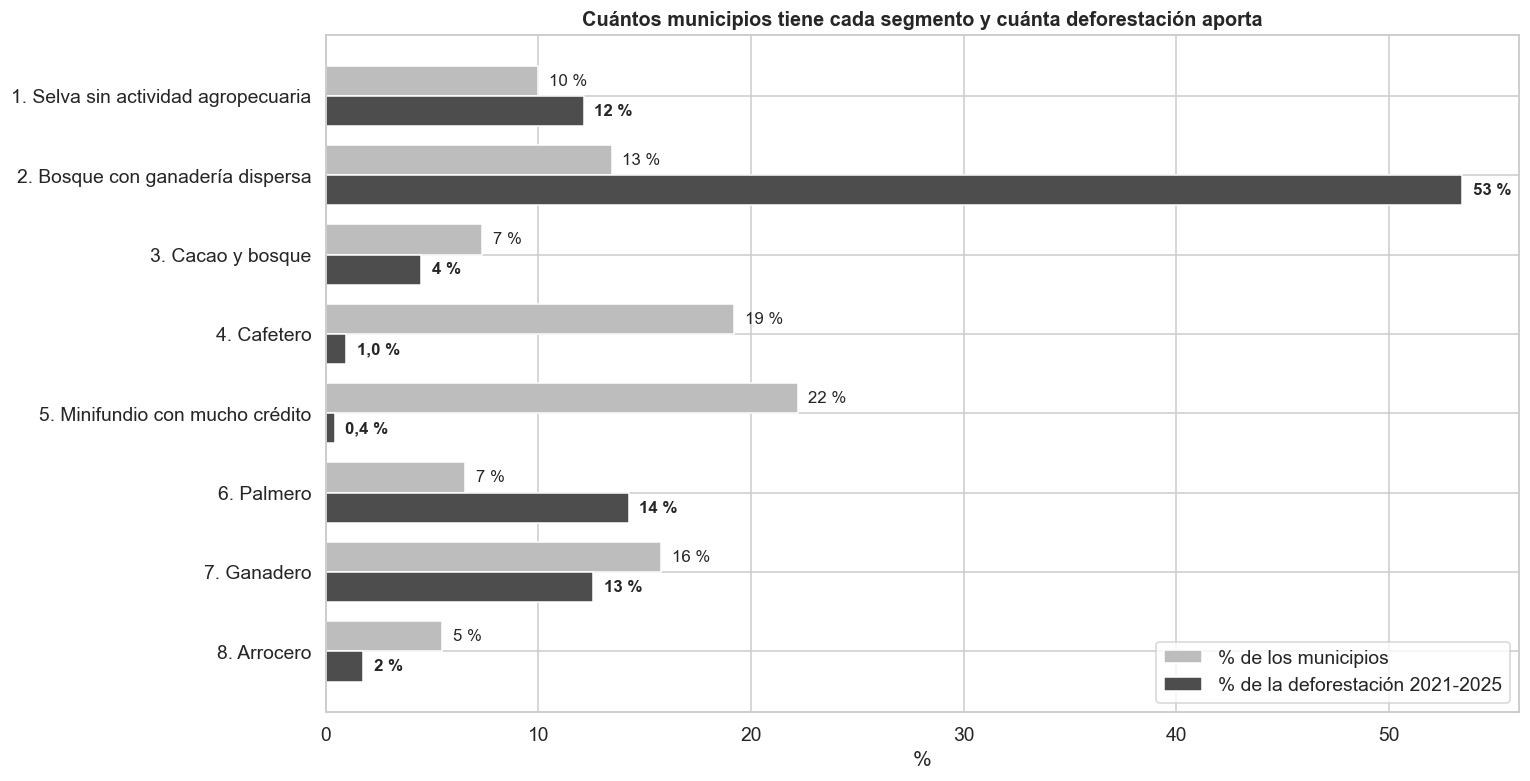

In [15]:
participacion = resumen[["% de los municipios", "% de la deforestación 2021-2025"]]
fig, ax = plt.subplots(figsize=(14, 8))
alto = 0.38
posiciones = np.arange(K)
ax.barh(posiciones - alto / 2, participacion["% de los municipios"], height=alto, color="#bdbdbd",
        label="% de los municipios")
ax.barh(posiciones + alto / 2, participacion["% de la deforestación 2021-2025"], height=alto, color="#4d4d4d",
        label="% de la deforestación 2021-2025")
for i, (m, d) in enumerate(participacion.values):
    ax.text(m + 0.5, i - alto / 2, f"{m:.0f} %", va="center", fontsize=11)
    ax.text(d + 0.5, i + alto / 2, f"{d:.1f} %".replace(".", ",") if d < 1 else f"{d:.0f} %", va="center",
            fontsize=11, weight="bold")
ax.set(yticks=posiciones, yticklabels=ETIQUETAS, xlabel="%",
       title="Cuántos municipios tiene cada segmento y cuánta deforestación aporta")
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.show()

**Qué se ve.**

- **La deforestación se concentra en cuatro perfiles.**
  - El bosque con ganadería dispersa (53 %), el palmero (14 %), el ganadero (13 %) y la selva (12 %) suman el 92 %
    de la deforestación con el 46 % de los municipios.
  - En el otro extremo, el cafetero y el minifundio tienen el 41 % de los municipios y solo el 1,4 % de la
    deforestación.
- **El segmento de bosque con ganadería dispersa aporta más de la mitad con el 13 % de los municipios.**
  - Ahí están Cartagena del Chairá, La Macarena, Calamar, San José del Guaviare, Solano y Puerto Guzmán: el arco de
    deforestación de la Amazonía.
  - Sus 5 municipios con más deforestación suman el 56 % del segmento.
- **Dentro de cada segmento, pocos municipios pesan mucho.**
  - En el palmero, 5 municipios suman el 87 % de la deforestación del segmento, con Mapiripán y Tibú a la cabeza.
  - En el ganadero suman el 83 %, con San Vicente del Caguán a la cabeza.
  - Por eso la mediana del segmento suele ser mucho más baja de lo que sugiere su total: la mayoría de los ganaderos
    deforesta poco, y unos pocos ganaderos de frontera deforestan muchísimo.
  - Las cajas son anchas por lo mismo. El segmento dice algo sobre cuánto deforesta un municipio, pero no lo dice
    todo.
- **La tasa cuenta otra historia.**
  - Los que pierden más rápido el bosque que les queda son el palmero (0,28 % al año, mediana), el arrocero
    (0,26 %) y el cacaotero (0,23 %).
  - El arrocero aporta poco en hectáreas porque le queda poco bosque (7 %), pero lo pierde rápido.
  - La selva y el bosque con ganadería dispersa tienen una tasa baja (0,08 %): pierden muchas hectáreas, pero tienen
    muchísimo bosque.
- **El cacaotero es el que más deforesta por km².** Su mediana es de 8,7 ha por 100 km² al año, y también es el que
  más alertas de GFW tiene (14,3). Coincide con las correlaciones de `panel_municipal_analisis.ipynb`: el cacao era
  la única variable asociada con más deforestación en los cinco grupos de tamaño de municipio.
- **Las dos fuentes coinciden.** Las alertas de GFW ordenan los segmentos casi igual que el IDEAM:
  - arriba, el cacaotero, el bosque con ganadería dispersa y la selva;
  - abajo, el minifundio, el ganadero y el arrocero.

## 7. Mapa de los segmentos

**Cómo se hace.** Se usan los límites municipales del DANE (Marco Geoestadístico Nacional 2025). Va un mapa por
segmento, en lugar de uno solo con siete colores, porque siete colores juntos no se distinguen bien, y menos con
daltonismo.

**Cómo leer el mapa.**

- En color, los municipios del segmento.
- En gris medio, los municipios rurales de otros segmentos.
- En gris claro, los que no son rurales y no entraron en la segmentación.

Municipios de la segmentación sin polígono en el mapa: []


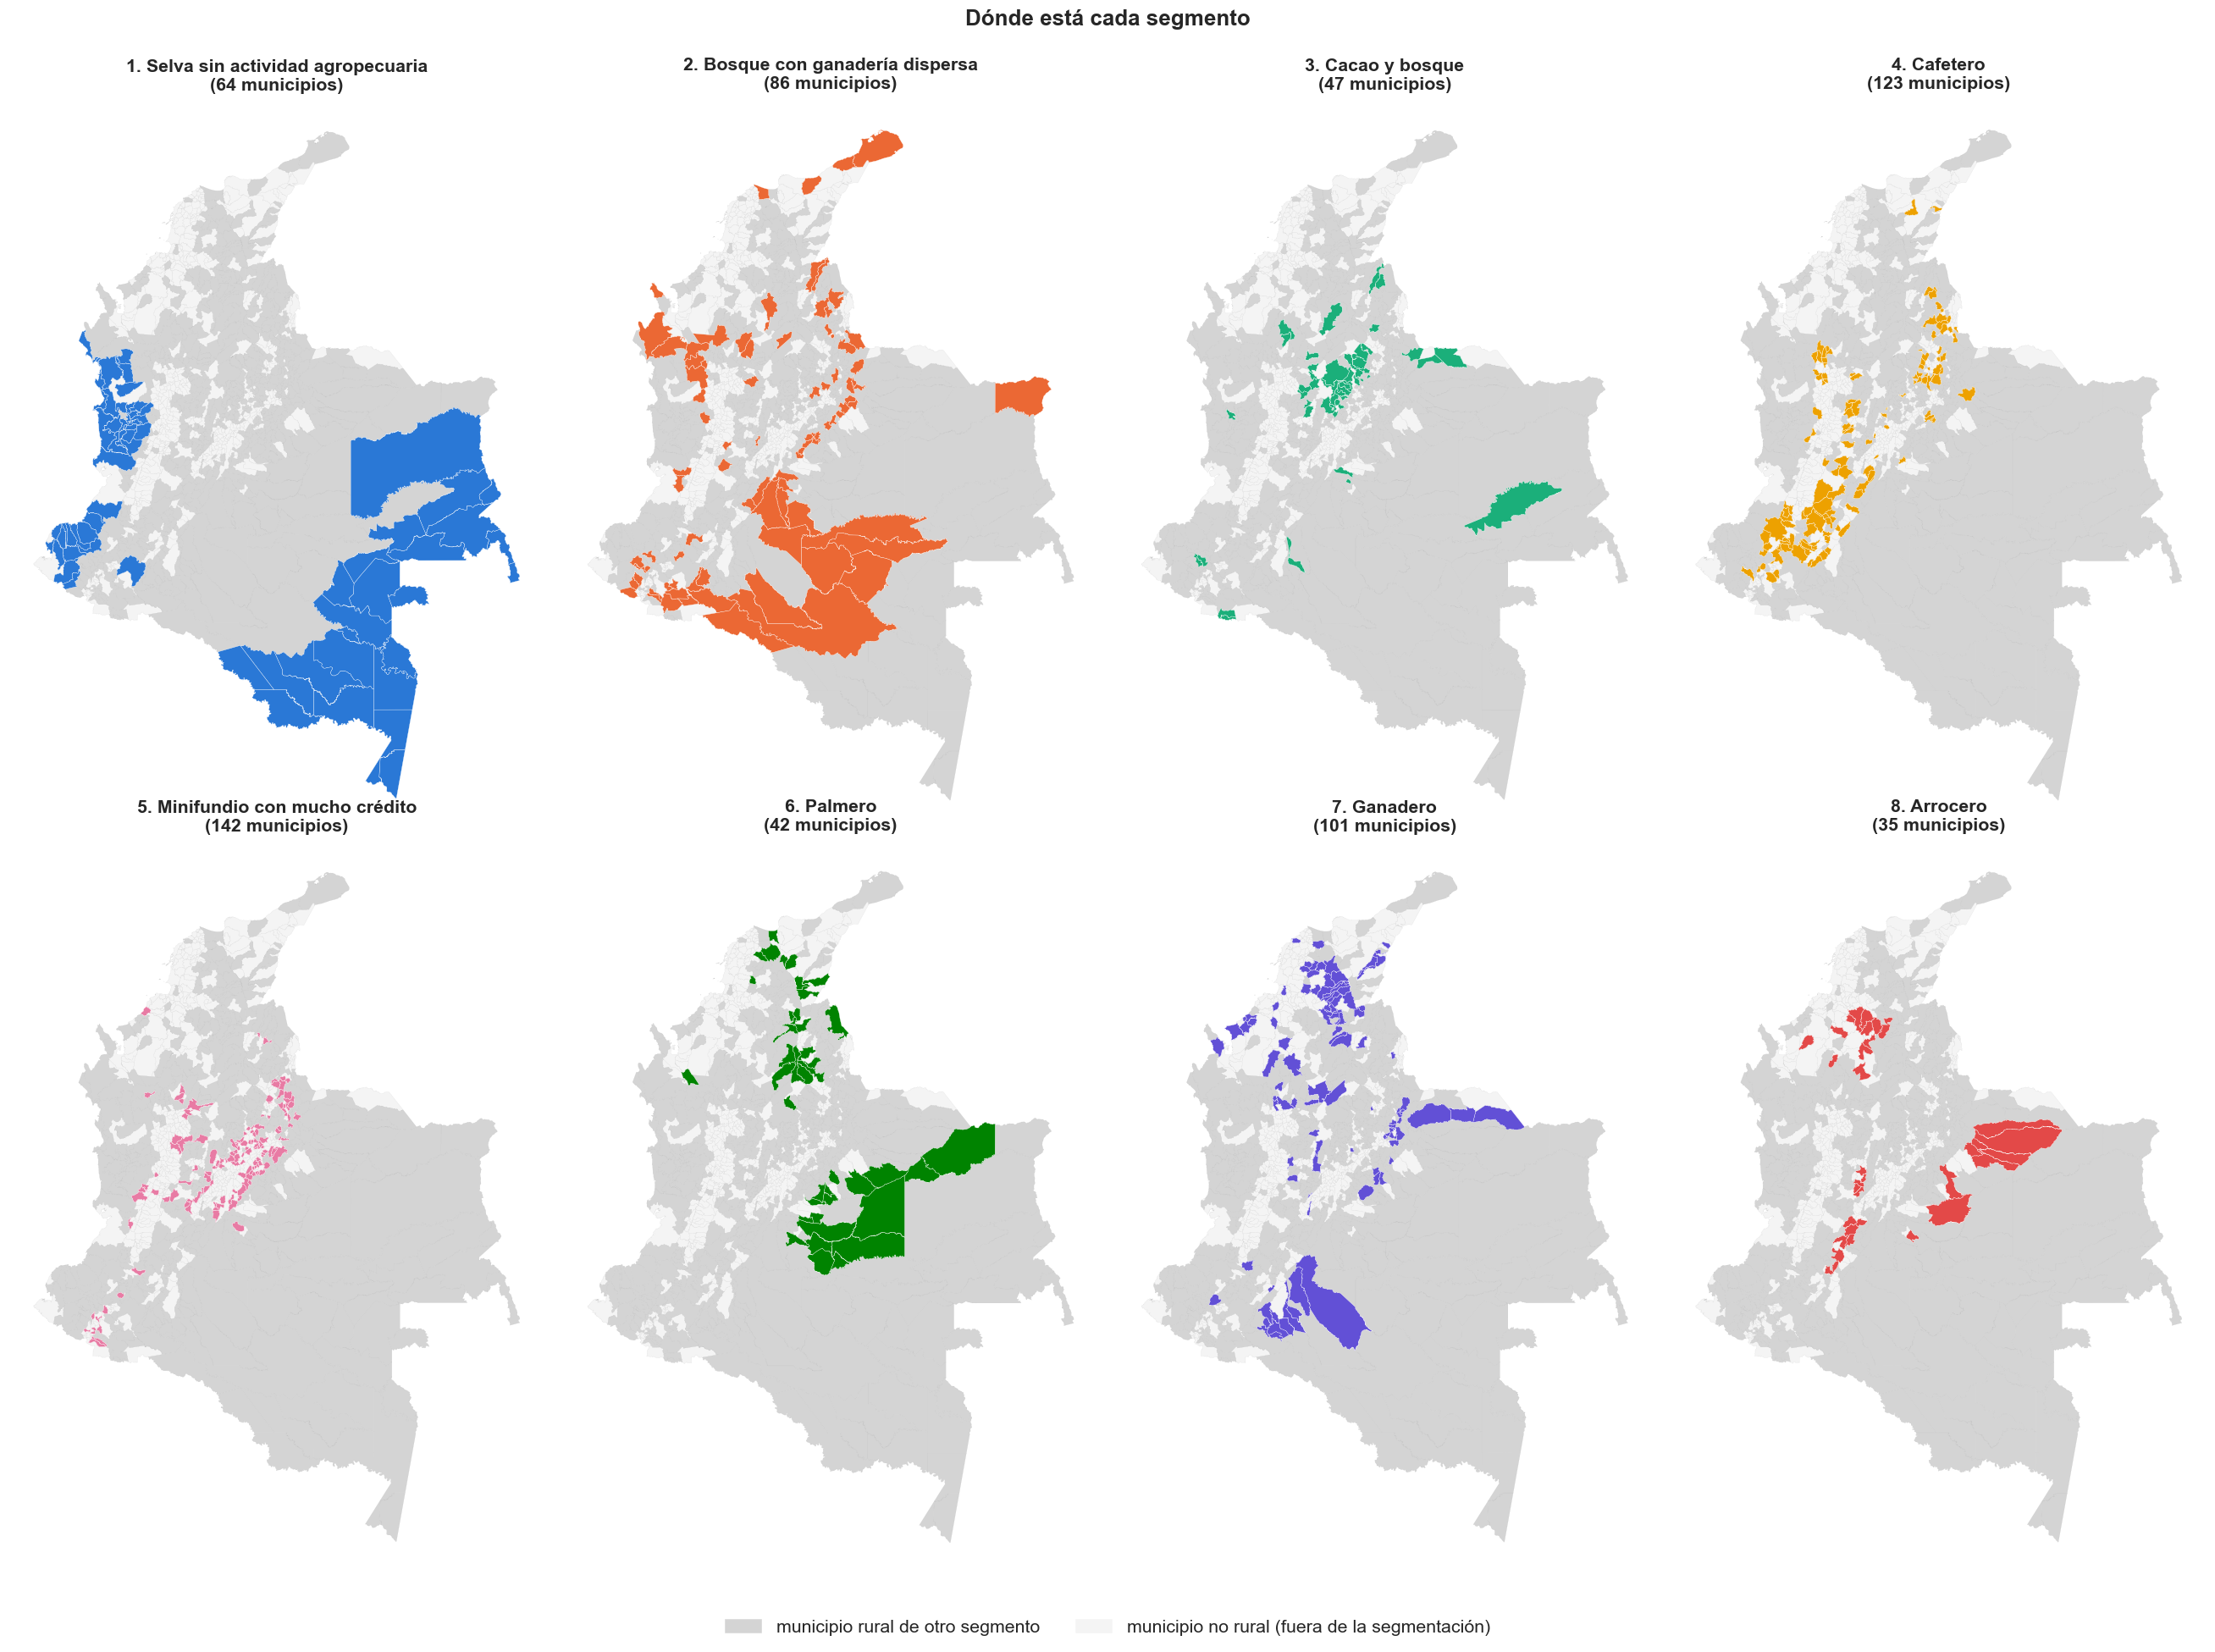

In [16]:
limites = gpd.read_file(DIR_LIMITES / "municipios_dane_mgn2025.geojson")[["mpio_cdpmp", "geometry"]]
continental = limites[~limites.mpio_cdpmp.str.startswith("88")]          # sin San Andrés: no tiene rurales
mapa = continental.merge(segmento, left_on="mpio_cdpmp", right_index=True, how="left")
print(f"Municipios de la segmentación sin polígono en el mapa: {sorted(set(segmento.index) - set(limites.mpio_cdpmp))}")

fig, axes = plt.subplots(2, 4, figsize=(24, 18))
for ax, s in zip(axes.flat, SEGS):
    mapa[mapa.segmento.isna()].plot(ax=ax, color="#f4f4f4", edgecolor="#d0d0d0", linewidth=0.1)
    mapa[mapa.segmento.notna() & (mapa.segmento != s)].plot(ax=ax, color="#d4d4d4", edgecolor="#bdbdbd",
                                                            linewidth=0.1)
    mapa[mapa.segmento == s].plot(ax=ax, color=COLOR[s], edgecolor="white", linewidth=0.2)
    ax.set_title(f"{SEGMENTOS[s]}\n({(segmento == s).sum()} municipios)", fontsize=14)
    ax.set_axis_off()
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#d4d4d4", "#f4f4f4")],
           labels=["municipio rural de otro segmento", "municipio no rural (fuera de la segmentación)"],
           loc="lower center", ncol=2, fontsize=14, frameon=False)
fig.suptitle("Dónde está cada segmento", weight="bold", fontsize=17)
plt.tight_layout(rect=(0, 0.03, 1, .97))
plt.show()

**Qué se ve.**

- La **selva** está en el Chocó, en la costa nariñense y en la Amazonía y la Orinoquía orientales: Amazonas, Guainía,
  Vaupés y Vichada.
- El **bosque con ganadería dispersa** forma un arco en el piedemonte amazónico (Caquetá, Guaviare, sur del Meta y
  Putumayo), justo entre la selva y las zonas ganaderas. Además aparece en manchas a lo largo de los Andes y de la
  costa Caribe.
- El **cafetero** y el **minifundio** ocupan la cordillera:
  - el cafetero, desde Nariño y Cauca hasta Antioquia y Santander;
  - el minifundio, en el altiplano cundiboyacense, en Santander y en el sur de Nariño.
- El **palmero**, el **ganadero** y el **arrocero** están en las tierras bajas:
  - el palmero, en el Meta, el Magdalena medio y el Caribe;
  - el ganadero, en el Caribe, el Magdalena medio, Arauca y San Vicente del Caguán;
  - el arrocero, en el Tolima, el Huila, Casanare y el bajo Cauca.

El mapa de la deforestación de `panel_municipal_analisis.ipynb` muestra el mismo arco amazónico. Es la zona donde el
segmento de bosque con ganadería dispersa toca a la selva.

## 8. Conclusiones y limitaciones

### Qué se puede decir

1. **Los municipios rurales sí forman grupos, pero sus fronteras no son nítidas.**
   - La silueta (0,26) duplica la de los datos sin estructura, pero indica una estructura débil.
   - Los 8 segmentos son estables frente al remuestreo, con un Jaccard de 0,81 a 0,97.
   - Los más nítidos son la selva y el palmero. Los menos nítidos, el ganadero y el de bosque con ganadería dispersa.
2. **La deforestación no está donde está el crédito.**
   - Los cuatro segmentos que más deforestan son los cuatro que menos crédito de producción reciben por km²: de 0,3 a
     8,4 M$.
   - Los que más crédito reciben, el minifundio (30 M$) y el cafetero (15 M$), casi no deforestan.
   - Donde hay deforestación, el poco crédito que llega va sobre todo a la ganadería: el 40 % en el segmento de
     bosque con ganadería dispersa y el 71 % en el ganadero.
   - Esto no quiere decir que el crédito proteja el bosque. Los segmentos con más crédito son de agricultura
     consolidada en la cordillera. Los que más deforestan tienen mucho bosque (la selva y el de bosque con ganadería
     dispersa) o tienen ganadería extensiva y palma. La diferencia puede venir del tipo de actividad, y no del
     crédito en sí.
   - Tampoco es solo cuestión de cuánto bosque queda: el palmero (10 % de bosque) y el ganadero (8 %) tienen menos
     bosque que el minifundio (13 %), y aun así deforestan mucho más.
3. **La deforestación se concentra en pocos perfiles.**
   - El bosque con ganadería dispersa (53 %), el palmero (14 %), el ganadero (13 %) y la selva (12 %) suman el 92 %
     con menos de la mitad de los municipios.
   - El cafetero y el minifundio, con el 41 % de los municipios, casi no deforestan (1,4 %).
4. **Las hectáreas y la tasa dicen cosas distintas.**
   - Las hectáreas se concentran donde hay mucho bosque y algo de ganado, sobre todo en el arco amazónico.
   - La tasa más alta está en los segmentos de palma, arroz y cacao, que pierden más rápido el bosque que les queda.
     Al arrocero le queda poco bosque (7 %), así que aporta pocas hectáreas (1,8 %) aunque lo pierda rápido.
5. **Dentro de cada segmento, unos pocos municipios explican casi todo.** En el palmero y el ganadero, 5 municipios
   suman más del 80 % de la deforestación del segmento. El segmento no reemplaza el análisis municipio a municipio.
6. **El cacao aparece otra vez.** El segmento cacaotero tiene la mayor deforestación por km² y las mayores alertas
   de GFW por km² (medianas), en línea con las correlaciones del análisis del panel municipal.

### Limitaciones

- **Es descriptivo.** Que un segmento deforeste mucho no prueba que su perfil productivo cause la deforestación. El
  ganado y la palma, por ejemplo, pueden llegar después de la tala, no antes.
- **El resultado depende de decisiones de método.** Las participaciones de los cultivos van sin transformar, así que
  los segmentos se arman por el cultivo que domina en cada municipio. Otras transformaciones, que les den más peso a
  los cultivos pequeños, pueden armar segmentos distintos.
- **Todas las variables pesan lo mismo, y cuatro de las diez son cultivos.** Con otra selección de variables los
  segmentos pueden cambiar.
- **Faltan actividades importantes.** La EVA no mide pastos ni coca. La coca puede estar detrás de parte de la
  deforestación en segmentos como el cacaotero o el palmero, por ejemplo en Tibú o en el Valle del Guamuez.
- **Los ceros pueden ser falta de reporte.** En los corregimientos departamentales de la Amazonía, que no haya
  cultivos, ganado ni crédito puede ser un vacío de información y no una ausencia real.
- **El crédito está en pesos corrientes.** Como todos los municipios se miden en los mismos años, la comparación
  entre ellos no se afecta.

## Exportar

Se guardan dos tablas:

- `modelos y clusters/resultados/segmentacion_municipios_clusters.xlsx`: un municipio por fila, con su cluster, el
  nombre y la descripción del cluster y su deforestación. Va ordenada por cluster, y dentro de cada cluster, de más a
  menos deforestación.
- `docs/tablas/segmentacion_municipios.xlsx`: lo mismo con todas las variables de la segmentación, más los
  resúmenes (perfil de cada segmento, deforestación por segmento, elección de k y estabilidad).

In [17]:
salida = (base[["nombre", "departamento", "region", "ruralidad"]]
          .join(segmento).assign(nombre_segmento=nombre_segmento)
          .join(X.rename(columns=NOMBRES))
          .join(deforestacion.rename(columns={"tasa": "tasa de deforestación (% del bosque por año)",
                                              "def_100km2": "deforestación IDEAM (ha por 100 km² al año)",
                                              "gfw_100km2": "alertas GFW (ha por 100 km² al año)",
                                              "def_total_ha": "deforestación IDEAM 2021-2025 (ha)"}))
          .sort_values(["segmento", "nombre"]))
destino = RAIZ / "docs" / "tablas" / "segmentacion_municipios.xlsx"
with pd.ExcelWriter(destino) as libro:
    salida.to_excel(libro, sheet_name="municipios")
    mediana.T.to_excel(libro, sheet_name="perfil (medianas)")
    resumen.to_excel(libro, sheet_name="deforestación por segmento")
    indices.to_excel(libro, sheet_name="elección de k")
    estab_seg.to_excel(libro, sheet_name="estabilidad")
print(f"Guardado: {destino.relative_to(RAIZ)} ({len(salida)} municipios)")

Guardado: docs\tablas\segmentacion_municipios.xlsx (640 municipios)


In [18]:
# Tabla de clusters para la carpeta de resultados: un municipio por fila
DESCRIPCIONES = {
    1: "Casi todo el municipio es bosque. Casi no tiene ganado, cultivos ni crédito. Está en el Pacífico y en la "
       "Amazonía y la Orinoquía orientales.",
    2: "Mucho bosque con algo de ganado. Muy poca agricultura y poco crédito, buena parte para la ganadería. Incluye "
       "el piedemonte amazónico, donde se concentra la deforestación.",
    3: "El cacao es el cultivo principal y el municipio conserva bastante bosque.",
    4: "El café es más de la mitad del área cosechada. Está en la cordillera.",
    5: "Municipios pequeños de hatos muy pequeños, con la mayor área cosechada y el crédito por km² más alto. Poco "
       "bosque.",
    6: "La palma es el cultivo principal. Hatos muy grandes y poco bosque.",
    7: "La mayor densidad de ganado, en hatos grandes, y la mayor parte del crédito va a la ganadería. Casi no tiene "
       "bosque.",
    8: "El arroz es el cultivo principal. Es el segmento con menos bosque.",
}
clusters = pd.DataFrame({
    "municipio": base.nombre,
    "departamento": base.departamento,
    "cluster": segmento,
    "nombre del cluster": nombre_segmento.str[3:],
    "descripción del cluster": segmento.map(DESCRIPCIONES),
    "deforestación IDEAM 2021-2025 (ha)": deforestacion.def_total_ha,
    "deforestación IDEAM (ha por 100 km² al año)": deforestacion.def_100km2,
    "tasa de deforestación (% del bosque por año)": deforestacion.tasa,
}).rename_axis("cod_dane").sort_values(["cluster", "deforestación IDEAM 2021-2025 (ha)"], ascending=[True, False])

DIR_RESULTADOS = RAIZ / "modelos y clusters" / "resultados"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
destino = DIR_RESULTADOS / "segmentacion_municipios_clusters.xlsx"
clusters.to_excel(destino, sheet_name="municipios")
print(f"Guardado: {destino.relative_to(RAIZ)} ({len(clusters)} municipios)")
clusters.head(10)

Guardado: modelos y clusters\resultados\segmentacion_municipios_clusters.xlsx (640 municipios)


,municipio,departamento,cluster,nombre del cluster,descripción del cluster,deforestación IDEAM 2021-2025 (ha),deforestación IDEAM (ha por 100 km² al año),tasa de deforestación (% del bosque por año)
cod_dane,,,,,,,,
99773,Cumaribo,Vichada,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,14334.6250,4.410654,0.076731
27491,Nóvita,Chocó,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,2947.0625,63.720270,0.719206
97001,Mitú,Vaupés,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,2941.8125,3.660109,0.038395
52250,El Charco,Nariño,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,2393.3750,19.944792,0.240790
27600,Río Quito,Chocó,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,2007.8750,55.389655,0.658739
52621,Roberto Payán,Nariño,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,1717.3125,24.533036,0.350548
94884,Puerto Colombia (CD),Guainía,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,1692.7500,2.173676,0.022707
97511,Pacoa (CD),Vaupés,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,1626.3750,2.290669,0.023416
94001,Inírida,Guainía,1,Selva sin actividad agropecuaria,Casi todo el municipio es bosque. Casi no tien...,1596.9375,1.980698,0.023748
